
## 🧠 From Biological to Artificial Neurons

Biological neurons form the inspiration for Artificial Neural Networks (ANNs). Each neuron receives electrical impulses through dendrites, integrates the signals in the soma (cell body), and fires an output via the axon if the input exceeds a threshold. Similarly, in ANNs, each artificial neuron sums weighted inputs and passes them through an activation function. Just as biological neurons form complex pathways in the brain, artificial neurons form layers in a neural network that can learn from data and simulate reasoning.

![Biological Neuron](./images/BioNeurons.png)



## ⚡ Neural Spikes vs. Compute Spikes

In the brain, neurons operate on an "all-or-nothing" basis: when a signal exceeds a threshold, an action potential fires, creating a spike in voltage over time. This is called the **integrate-and-fire** model. In deep learning, training large neural networks also generates spike-like behavior — but in CPU or GPU utilization! Spikes in electrical voltage in biological neurons mirror spikes in compute power during heavy processing. This analogy helps us appreciate how ANN training simulates (inspired by) the nervous system.

![Neuron Spikes](./images/NeuronSpikes.png)



## 🧮 Mathematical Model of an Artificial Neuron

![Deel Learning High-Level View](./images/DL_HighLevelView.png)

Each neuron computes a weighted sum of its inputs, adds a bias, and passes the result through an activation function:

$$
z = \sum_{j=0}^{m} w_j x_j = w_0 x_0 + w_1 x_1 + \cdots + w_m x_m
$$

Then, the output of the neuron is:

$$
\hat{y} = A(z)
$$

Where:
- $x_0$ is the bias input (typically set to 1)
- $w_j$ are the weights
- $A(z)$ is the activation function

This process models how neurons integrate input and "decide" whether to activate.




## 🧩 Activation Functions

Activation functions introduce non-linearity into neural networks, allowing them to model complex relationships.

### 🔹 Identity
$$
g(x) = x
$$
Linear output, rarely used alone.

### 🔹 Binary Step
$$
g(x) = 
\begin{cases}
0 & \text{if } x < 0 \\
1 & \text{if } x \geq 0
\end{cases}
$$
Used in early perceptrons.

### 🔹 Sigmoid
$$
\sigma(x) = \frac{1}{1 + e^{-x}}
$$
Smooth, output between 0 and 1. Good for probabilities.

### 🔹 Tanh
$$
\tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}}
$$
Output between -1 and 1. Centered around zero.

### 🔹 ReLU (Rectified Linear Unit)
$$
\text{ReLU}(x) = \max(0, x)
$$
Default for hidden layers. Efficient and sparse.




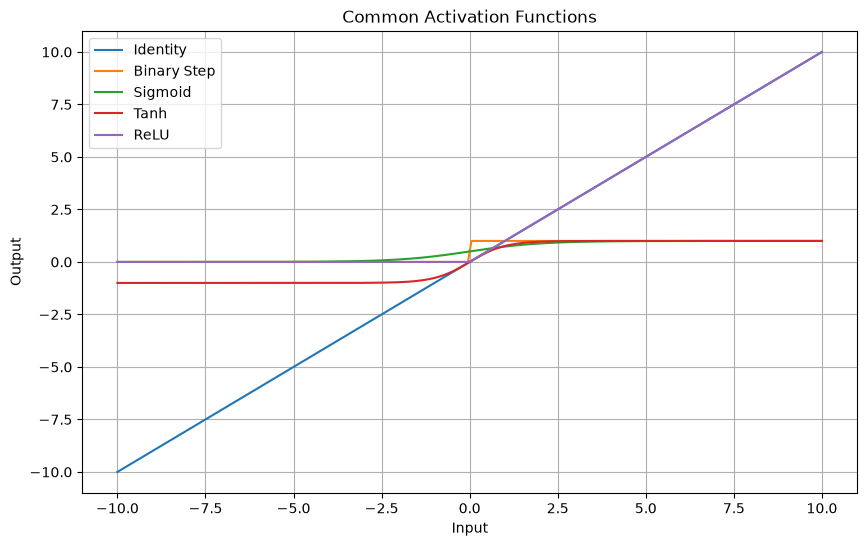

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-10, 10, 200)
identity = x
binary_step = np.where(x >= 0, 1, 0)
sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)
relu = np.maximum(0, x)

plt.figure(figsize=(10, 6))
plt.plot(x, identity, label='Identity')
plt.plot(x, binary_step, label='Binary Step')
plt.plot(x, sigmoid, label='Sigmoid')
plt.plot(x, tanh, label='Tanh')
plt.plot(x, relu, label='ReLU')
plt.title("Common Activation Functions")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)
plt.legend()
plt.show()


### 🧪 Interactive Experiment: TensorFlow Playground

Want to *experiment with neural networks* in real-time?

Click the link below to explore an interactive simulation using the **tanh activation function** and a **circular dataset**. Adjust parameters like learning rate, number of layers, and input features — and observe how the decision boundaries evolve.

👉 **[Launch the TensorFlow Playground Simulation](https://playground.tensorflow.org/#activation=tanh&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.03&regularizationRate=0&noise=0&networkShape=4,2&seed=0.48465&showTestData=false&discretize=false&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false)**

![Playground Preview](https://raw.githubusercontent.com/tensorflow/playground/master/images/playground.png)

🧠 Try changing the:
- Activation function (ReLU, tanh, sigmoid)
- Network shape (number of layers and neurons)
- Learning rate and batch size
- Input features (x, y, x², sin(x), etc.)

This is a powerful tool to build intuition about how neural networks **learn patterns**!



### 🗣️ Code Walkthrough Talking Points

- Each function maps input `x` to a transformed output — this controls how neurons activate.
- `Binary Step` is simple and fast but non-differentiable.
- `Sigmoid` and `Tanh` are smooth but suffer from vanishing gradients.
- `ReLU` is widely used due to efficiency and sparse activation.


## 🧠 Case Study: Are We Going to Canada's Wonderland?
We will now implement a simple artificial neural network using **PyTorch** to predict whether we’ll go to Canada's Wonderland based on three inputs:

- **X₁**: Weather — 1 if sunny, 0 if rainy
- **X₂**: Ticket queue — 1 if short, 0 if long
- **X₃**: Health — 1 if healthy, 0 if unwell

Each input has an associated **weight**, and the network uses a **bias** and a **sigmoid activation function** to generate a confidence value.

### 📊 Visual Summary: ANN Case Study – Are We Going to Canada's Wonderland?

Below is a visual walkthrough of the single-neuron prediction model:

| Slide 1 | Slide 2 |
|--------|--------|
| ![Slide 1](./images/ANN_1.png) | ![Slide 2](./images/ANN_2.png) |

| Slide 3 | Slide 4 |
|--------|--------|
| ![Slide 3](./images/ANN_3.png) | ![Slide 4](./images/ANN_4.png) |

| Slide 5 | Slide 6 |
|--------|--------|
| ![Slide 5](./images/ANN_5.png) | ![Slide 6](./images/ANN_6.png) |


### 🔢 Step 1: Prediction Function
We compute the neuron output $\hat{y}$ as:

$$
\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}, \quad \text{where} \quad z = w_1 x_1 + w_2 x_2 + w_3 x_3 + b
$$

In our case:

- $x = [1, 0, 1]$
- $w = [5, 2, 4]$
- $b = -3$

In [2]:
import torch
import torch.nn as nn

# Inputs and weights
x = torch.tensor([1.0, 0.0, 1.0])
weights = torch.tensor([5.0, 2.0, 4.0])
bias = -3.0

# Linear combination
z = torch.dot(weights, x) + bias

# Sigmoid activation
sigmoid = torch.sigmoid(z)
print(f"z = {z.item():.2f}")
print(f"Predicted output (sigmoid) = {sigmoid.item():.4f}")

z = 6.00
Predicted output (sigmoid) = 0.9975


### 📈 Understanding the Output of Our Neuron

In the previous code cell, we computed the neuron's output using PyTorch:

```python
z = torch.dot(weights, x) + bias
sigmoid = torch.sigmoid(z)
```

#### 🔢 Here's how it breaks down:

Let’s plug in the numbers used in the slide (also shown in the code):

* Inputs: ( x = [1, 0, 1] )
* Weights: ( w = [5, 2, 4] )
* Bias: ( b = -3 )

The **linear combination** is computed as:

$$
\hat{y} = z = w_1x_1 + w_2x_2 + w_3x_3 + b = (1 \times 5) + (0 \times 2) + (1 \times 4) - 3 = 5 + 0 + 4 - 3 = 6
$$

Then, we pass this result through the **sigmoid activation function**:

$$
f(z) = \frac{1}{1 + e^{-z}} = \frac{1}{1 + e^{-6}} \approx 0.9975
$$

This output is the **model’s confidence** (close to 1), which matches the slide’s annotation:

> “Therefore, we are going to Wonderland!”

🧠 **Interpretation**:

* Since $ \hat{y} = 6 $ and our threshold $ \tau = 3 $, and $ \hat{y} > \tau $, the neuron **fires**.
* The sigmoid output $ \approx 0.9975 $ tells us the model is **very confident** in its decision.

✅ Slide 2 in the table above, and the code are in **perfect agreement**.


### 💬 Talking Points
- We treat inputs like "sunny", "short queue", and "healthy" as binary features.
- The weighted sum (`z`) captures how favorable conditions are.
- Applying `sigmoid(z)` maps the decision to a probability.

### ❌ Step 2: Error Calculation
We compare the predicted value with the actual label:

$$
E = y - \hat{y}
$$

If the actual value is 1 (we should go), but our prediction is too low, we compute the error and update the weights.

In [3]:
y = torch.tensor(1.0)
error = y - sigmoid
print(f"Error = {error.item():.4f}")

Error = 0.0025


### 🧠 Talking Point: Why is the Error Different to that in the slides?

There’s an important distinction between **raw neuron output** $ \hat{y} $ and the **activated output** (confidence) $ f(z) $, which explains the discrepancy between:

* The error calculation in slide 4 in the table above is:
  $$
  E = y - \hat{y} = 1 - 6 = -5
  $$

* However, PyTorch code’s error calculation in the output above was:
  $$
  E = y - f(z) = 1 - 0.9975 = 0.0025
  $$

#### 🤔 What's happening?

* In **slides 4, 5 and 6**, the error is calculated using the raw linear output:
  $$
  \hat{y} = w_1x_1 + w_2x_2 + w_3x_3 + b = 6
  $$
  This is a **pre-activation** value, often used in gradient calculations during **backpropagation**.

* In the **code**, the error is computed using the **post-activation sigmoid output**:
  $$
  f(z) = \frac{1}{1 + e^{-6}} \approx 0.9975
  $$
  This represents the neuron's **confidence** in the prediction — suitable for binary classification.

#### 🧵 Summary:

* Use $ \hat{y} $ for training updates (e.g., computing loss and gradients).
* Use $ f(z) $ for interpreting prediction confidence.
* Both perspectives are valid — they serve **different roles** in learning and inference.

✅ This difference helps students understand **forward pass vs. backward pass** in training neural networks.


### 🔁 Step 3: Weight Update with Gradient Descent
Using a learning rate $\eta = 0.1$, we update each weight:

$$
w_j = w_j - \eta \cdot \frac{\partial L}{\partial w_j}
$$

We use PyTorch autograd to perform backpropagation.

In [4]:
x = x.clone().detach().requires_grad_(True)
weights = weights.clone().detach().requires_grad_(True)

z = torch.dot(weights, x) + bias
y_hat = torch.sigmoid(z)
loss = (y_hat - y) ** 2
loss.backward()

lr = 0.1
with torch.no_grad():
    weights -= lr * weights.grad
    print(f"Updated weights: {weights}")

Updated weights: tensor([5.0000, 2.0000, 4.0000], requires_grad=True)


> ### 🏠 Homework Challenge
>
> Study how to update the weights using **Gradient Descent**.
>
> 📌 **Question**: How is this update rule related to **Backpropagation** in multi-layer neural networks?
>

# 🧠 Single-Layer Perceptron: Visualizing Weights, Bias, and Activation

## Case #1 : C = A

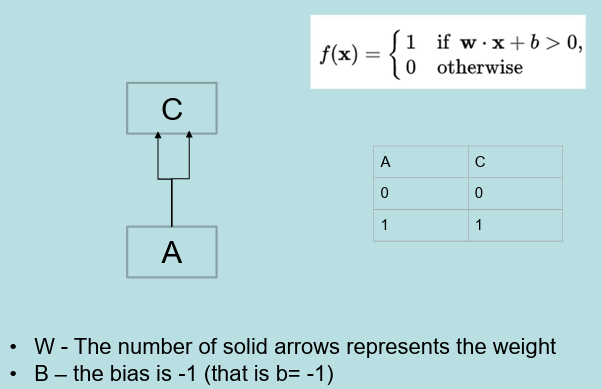



This perceptron has:

- One input node **A**
- One output node **C**
- Weight **w = 2** (represented by 2 arrows)
- Bias **b = -1**
- Activation function is a **step function**:
  
  $$
  f(x) = 
  \begin{cases} 
  1 & \text{if } w \cdot x + b > 0 \\
  0 & \text{otherwise}
  \end{cases}
  $$

Let's reproduce this in code using both **PyTorch** and **TensorFlow**.

---

## 🧪 PyTorch Implementation

Make sure to install these libraries in your virtual environment before you run the code:

```python
!pip install torch tensorflow notebook

```
```python
import torch

# Define weight and bias
w = torch.tensor(2.0)
b = torch.tensor(-1.0)

# Step activation function
def step(x):
    return 1 if x > 0 else 0

# Run for all inputs A = 0 or 1
for A in [0, 1]:
    x = torch.tensor(A, dtype=torch.float32)
    linear_output = w * x + b
    y = step(linear_output)
    print(f"Input A: {A} → Linear Output: {linear_output:.1f} → Output C: {y}")


In [5]:
import tensorflow as tf

# Define weight and bias
w = tf.constant(2.0)
b = tf.constant(-1.0)

# Step activation function
def step(x):
    return tf.where(x > 0, 1, 0)

# Run for all inputs A = 0 or 1
for A in [0, 1]:
    x = tf.constant(float(A))
    linear_output = w * x + b
    y = step(linear_output)
    print(f"Input A: {A} → Linear Output: {linear_output.numpy():.1f} → Output C: {y.numpy()}")


Input A: 0 → Linear Output: -1.0 → Output C: 0
Input A: 1 → Linear Output: 1.0 → Output C: 1


Here’s a side-by-side style comparison and integrated implementation of the Single-Layer Perceptron using both PyTorch and TensorFlow, formatted for a Jupyter Notebook. The goal is to clearly demonstrate how both frameworks approach the same logic:

In [6]:
# --- Imports ---
import torch
import tensorflow as tf

# --- Model Parameters (same for both) ---
weight = 2.0
bias = -1.0

# --- Step Activation Function (same logic) ---
def step(x):
    return 1 if x > 0 else 0

# --- Input values to test ---
inputs = [0, 1]

# --- PyTorch Implementation ---
print("🔵 PyTorch Perceptron Output")
for A in inputs:
    x_torch = torch.tensor(float(A))
    linear_output = weight * x_torch + bias
    output = step(linear_output.item())
    print(f"Input A: {A} → Linear: {linear_output.item():.1f} → Output C: {output}")

print("\n🟢 TensorFlow Perceptron Output")
# --- TensorFlow Implementation ---
for A in inputs:
    x_tf = tf.constant(float(A))
    linear_output = weight * x_tf + bias
    output = step(linear_output.numpy())
    print(f"Input A: {A} → Linear: {linear_output.numpy():.1f} → Output C: {output}")


🔵 PyTorch Perceptron Output
Input A: 0 → Linear: -1.0 → Output C: 0
Input A: 1 → Linear: 1.0 → Output C: 1

🟢 TensorFlow Perceptron Output
Input A: 0 → Linear: -1.0 → Output C: 0
Input A: 1 → Linear: 1.0 → Output C: 1


### 🧠 AND Gate as a Perceptron: PyTorch vs TensorFlow

### Case #2 : C = A and B

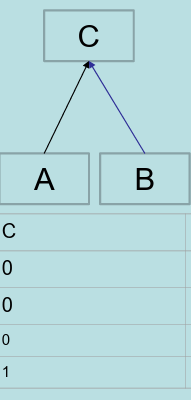

🧾 Model Description
Inputs: A, B

- Weight for A: 1
- Weight for B: 1
- Bias: -1.5

Activation: Step function (binary output)

In [7]:
import torch
import tensorflow as tf

# Shared configuration
weights = [1.0, 1.0]  # w_A = 1, w_B = 1
bias = -1.5
inputs = [(0, 0), (1, 0), (0, 1), (1, 1)]

def step(x):
    return 1 if x > 0 else 0

print("🔵 PyTorch Perceptron Output")
for A, B in inputs:
    x = torch.tensor([A, B], dtype=torch.float32)
    w = torch.tensor(weights)
    linear_output = torch.dot(w, x) + bias
    output = step(linear_output.item())
    print(f"Input A={A}, B={B} → Linear: {linear_output.item():.1f} → Output C: {output}")

print("\n🟢 TensorFlow Perceptron Output")
for A, B in inputs:
    x = tf.constant([A, B], dtype=tf.float32)
    w = tf.constant(weights)
    linear_output = tf.reduce_sum(w * x) + bias
    output = step(linear_output.numpy())
    print(f"Input A={A}, B={B} → Linear: {linear_output.numpy():.1f} → Output C: {output}")


🔵 PyTorch Perceptron Output
Input A=0, B=0 → Linear: -1.5 → Output C: 0
Input A=1, B=0 → Linear: -0.5 → Output C: 0
Input A=0, B=1 → Linear: -0.5 → Output C: 0
Input A=1, B=1 → Linear: 0.5 → Output C: 1

🟢 TensorFlow Perceptron Output
Input A=0, B=0 → Linear: -1.5 → Output C: 0
Input A=1, B=0 → Linear: -0.5 → Output C: 0
Input A=0, B=1 → Linear: -0.5 → Output C: 0
Input A=1, B=1 → Linear: 0.5 → Output C: 1


### 🧠 OR Gate as a Perceptron: PyTorch vs TensorFlow

### Case #3 : C = A or B

🖼️ Diagram


💡 Code Walkthrough Talking Points

- Linear combination: The perceptron computes w₁·A + w₂·B + b. That’s the raw "score".
- Step activation: If the result > 0, output is 1; otherwise 0 — mimicking binary logic gates.
- Bias control: The bias -1.5 ensures that both A and B must be 1 to activate the output.

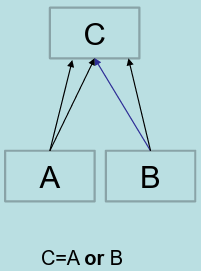

🧾 Model Description
Inputs: A, B

Weights:

- A → C: 1
- B → C: 2
- Bias: -0.5

Activation: Step function

In [8]:
import torch
import tensorflow as tf

# Model parameters
weights = [1.0, 2.0]  # A → 1, B → 2
bias = -0.5
inputs = [(0, 0), (1, 0), (0, 1), (1, 1)]

def step(x):
    return 1 if x > 0 else 0

print("🔵 PyTorch OR Perceptron Output")
for A, B in inputs:
    # torch.tensor creates a new tensor (multi-dimensional array) from the given data.
    # Here, it converts the Python list [A, B] into a PyTorch tensor of type float32.
    x = torch.tensor([A, B], dtype=torch.float32)
    w = torch.tensor(weights)
    # torch.dot computes the dot product of two 1D tensors (vectors).
    # For example, torch.dot(w, x) = w[0]*x[0] + w[1]*x[1]
    linear_output = torch.dot(w, x) + bias
    output = step(linear_output.item())
    print(f"Input A={A}, B={B} → Linear: {linear_output.item():.1f} → Output C: {output}")

print("\n🟢 TensorFlow OR Perceptron Output")
for A, B in inputs:
    # tf.constant creates a constant tensor from the given data.
    # Here, it converts the Python list [A, B] into a TensorFlow tensor of type float32.
    x = tf.constant([A, B], dtype=tf.float32)
    w = tf.constant(weights)
    linear_output = tf.reduce_sum(w * x) + bias
    output = step(linear_output.numpy())
    print(f"Input A={A}, B={B} → Linear: {linear_output.numpy():.1f} → Output C: {output}")


🔵 PyTorch OR Perceptron Output
Input A=0, B=0 → Linear: -0.5 → Output C: 0
Input A=1, B=0 → Linear: 0.5 → Output C: 1
Input A=0, B=1 → Linear: 1.5 → Output C: 1
Input A=1, B=1 → Linear: 2.5 → Output C: 1

🟢 TensorFlow OR Perceptron Output
Input A=0, B=0 → Linear: -0.5 → Output C: 0
Input A=1, B=0 → Linear: 0.5 → Output C: 1
Input A=0, B=1 → Linear: 1.5 → Output C: 1
Input A=1, B=1 → Linear: 2.5 → Output C: 1


### 💡 Code Walkthrough Talking Points
Weighting B more: Input B has a stronger influence on C (weight = 2), reflecting the blue arrow.

OR logic: With bias = -0.5, even a single active input (A or B) is enough to activate C.

Threshold control: The bias lowers the threshold so only one input needs to be active.


## 🧠 Inhibitory Logic in Perceptrons: Modeling C = A ∧ ¬B

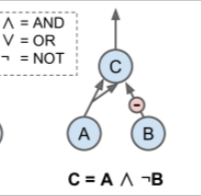

---

### 🔍 Description

- **Inputs**:
  - A (excitatory, weight = +1)
  - B (inhibitory, weight = -1)
- **Bias**: -0.5
- **Activation**: Step function

This neuron fires **only if** A is ON and B is OFF.

---


In [9]:
import torch
import tensorflow as tf

# Inputs: A, B
inputs = [(0, 0), (1, 0), (0, 1), (1, 1)]
weights = [1.0, -1.0]  # A=+1, B=-1
bias = -0.5

def step(x):
    return 1 if x > 0 else 0

print("🔵 PyTorch Implementation")
for A, B in inputs:
    print(f"Input A={A}, B={B}")
    x = torch.tensor([A, B], dtype=torch.float32)
    w = torch.tensor(weights)
    # torch.dot computes the dot product of two tensors.
    # Here, it calculates the weighted sum of inputs: z = w[0]*x + w[1]*x + bias
    z = torch.dot(w, x) + bias
    print(f"z (weighted sum) = {z.item():.1f}")
    y = step(z.item())
    print(f"A={A}, B={B} → z={z.item():.1f} → C={y}")

print("\n🟢 TensorFlow Implementation")
for A, B in inputs:
    x = tf.constant([A, B], dtype=tf.float32)
    w = tf.constant(weights)
    z = tf.reduce_sum(w * x) + bias
    y = step(z.numpy())
    print(f"A={A}, B={B} → z={z.numpy():.1f} → C={y}")


🔵 PyTorch Implementation
Input A=0, B=0
z (weighted sum) = -0.5
A=0, B=0 → z=-0.5 → C=0
Input A=1, B=0
z (weighted sum) = 0.5
A=1, B=0 → z=0.5 → C=1
Input A=0, B=1
z (weighted sum) = -1.5
A=0, B=1 → z=-1.5 → C=0
Input A=1, B=1
z (weighted sum) = -0.5
A=1, B=1 → z=-0.5 → C=0

🟢 TensorFlow Implementation
A=0, B=0 → z=-0.5 → C=0
A=1, B=0 → z=0.5 → C=1
A=0, B=1 → z=-1.5 → C=0
A=1, B=1 → z=-0.5 → C=0



### 💬 Code Walkthrough Talking Points

- 🧲 **Inhibition as negative weight**: Neuron B has a weight of -1, which reduces the activation signal.
- 🚦 **Neuron must be off**: When B = 1, the negative weight prevents activation. This models logic gates with inhibition.
- 🧠 **Implements A AND NOT B**: This is a classic example of using simple perceptrons for logic circuits.


## 🧠 Challenge

### Use a Single Layer Perceptron to decide if you will go to the movies

Source: https://youtu.be/OFbnpY_k7js?si=aLIumFjjRtAMtxtm

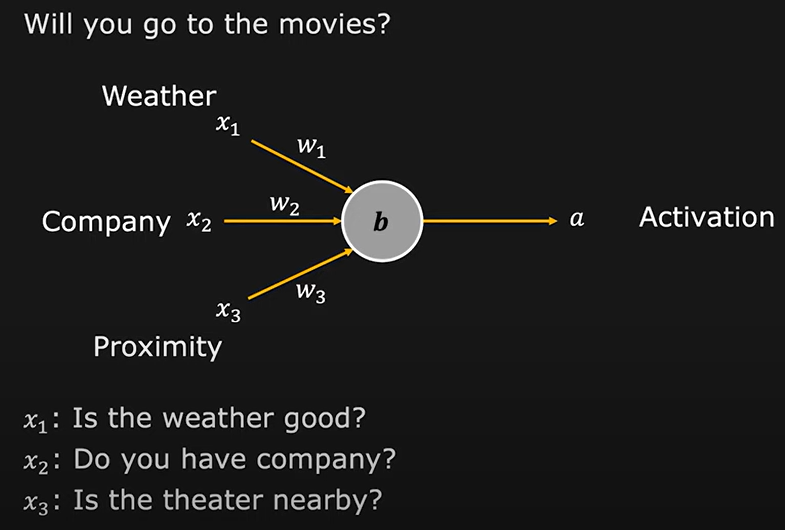

You can add and play with your own weights and biases.
Use the same activation function as in the examples above.
Add a talking point you can share with the class.

Here is a complete code cell implementing the single-layer perceptron to answer:

"Will you go to the movies?"
Based on: weather, company, and proximity

We'll use:

- Binary inputs x₁, x₂, x₃
- Weights: w₁ = 1.0 (weather), w₂ = 1.0 (company), w₃ = 1.0 (proximity)
- Bias b = -2.5 to require at least 3 "yes" answers to return a 1 (i.e., go to the movies)

In [10]:
from itertools import product

# Inputs: weather (x1), company (x2), proximity (x3)
weights = [1.0, 1.0, 1.0]   # w1, w2, w3
bias = -2.5                 # threshold: all three must be 1 for output = 1

def step(z):
    return 1 if z > 0 else 0

print("x1 x2 x3 | z      | Output")
print("----------------------------")
for x in product([0, 1], repeat=3):
    z = sum(w * xi for w, xi in zip(weights, x)) + bias
    output = step(z)
    print(f"{x[0]}  {x[1]}  {x[2]} | {z:>5.1f} |   {output}")


x1 x2 x3 | z      | Output
----------------------------
0  0  0 |  -2.5 |   0
0  0  1 |  -1.5 |   0
0  1  0 |  -1.5 |   0
0  1  1 |  -0.5 |   0
1  0  0 |  -1.5 |   0
1  0  1 |  -0.5 |   0
1  1  0 |  -0.5 |   0
1  1  1 |   0.5 |   1


🧠 Interpretation

- x₁: Is the weather good?
- x₂: Do you have company?
- x₃: Is the theater nearby?

Output 1 → You will go to the movies.

Output 0 → You won't go.

This simulates human-like logic where all conditions must be favorable.

### 🧠 How Does the Perceptron Behave as a Linear Classifier?

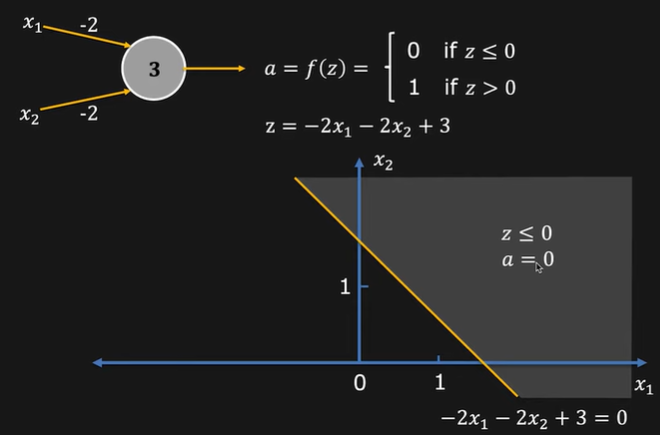

### 🧩 What's Happening in This Diagram?

- The **perceptron** computes:
  
  \[
  z = -2x_1 - 2x_2 + 3
  \]

- It then applies the **step activation**:
  
  $$
  a = 
  \begin{cases}
  1 & \text{if } z > 0 \\
  0 & \text{if } z \leq 0
  \end{cases}
  $$


### 📊 What Is the Yellow Line?

- It's the **decision boundary**, found by setting $z = 0$.
- That gives:

  $$
  -2x_1 - 2x_2 + 3 = 0 \quad \Rightarrow \quad x_2 = -x_1 + 1.5
  $$

- This line separates the input space into:

  - 🟡 **Above the line** → $z > 0$ → $a = 1$
  - ⚫ **Below or on the line** → $z \leq 0$ → $a = 0$


### 🧠 Why It Matters

This shows that a **single-layer perceptron classifies data using a straight line** (in 2D) — a **linear decision boundary**. If the inputs are linearly separable, the perceptron can perfectly classify them.


## 🧠 Challenge

Implement the Prostate Cancer prediction ANN in the Deep Learning Fundamentals class notes.

To do this:

1. Run and understand the provided Canada's Wonderland use case study and code provided with this workshop notebook.
2. Use them as a guide to implement new code and Markdown to explain it.
3. Add your Markdown, code and three talking points in the space below.

Keep the contents of the workshop and just add the new contents. 
Then copy the entire Jupyter notebook your own repository, and share the link to it for review.
Feel free to add the images folder so the notebook markdown shows the graphics it originally came with.


---
# Team Extensions

Everything above this point is the original workshop.

## Activation Functions, Logic Gates & the Movie Challenge
*Author: Rangeetha*

In [11]:

import numpy as np
import matplotlib.pyplot as plt
import torch
import tensorflow as tf
from itertools import product

torch.manual_seed(0)
tf.random.set_seed(0)
np.set_printoptions(precision=4, suppress=True)
print(f"PyTorch {torch.__version__} | TensorFlow {tf.__version__}")

PyTorch 2.15.0 | TensorFlow 2.21.0


### Activation functions: input range and derivatives

#### From a biological neuron to an artificial one

| Biological neuron | Artificial neuron |
|---|---|
| **Dendrites** receive signals from other neurons | **Inputs** $x_1, \dots, x_m$ |
| **Synapses** make some connections stronger than others | **Weights** $w_1, \dots, w_m$ (a negative weight is an *inhibitory* synapse) |
| The **cell body (soma)** adds up all incoming signals | **Weighted sum** $\sum_j w_j x_j$ |
| The neuron's **firing threshold** | **Bias** $b$ (equivalently $w_0$ with a constant input $x_0 = 1$) |
| The neuron **fires** an impulse down the **axon** only if the summed signal passes the threshold | The **activation function** $A(z)$ turns the sum into an output $\hat{y}$ |

So every neuron in this notebook does two steps:

$$
z = \sum_{j=1}^{m} w_j x_j + b \qquad\qquad \hat{y} = A(z)
$$

* **Weighted inputs:** a large positive $w_j$ means input $j$ pushes strongly towards firing, a negative $w_j$ pushes against it, and $w_j = 0$ means the input is ignored.
* **Bias:** shifts the threshold. With $b = -1.5$, the weighted inputs must add up to more than 1.5 before $z > 0$. Raising the bias makes the neuron easier to fire, and lowering it makes the neuron harder to fire.

#### The five activation functions and their derivatives

Derivatives matter because gradient descent (last section) multiplies by $A'(z)$ when it updates the weights. If $A'(z) \approx 0$, the weights barely change.

| Function | Formula $A(z)$ | Derivative $A'(z)$ | Output range |
|---|---|---|---|
| Identity | $z$ | $1$ | $(-\infty, \infty)$ |
| Binary step | $\begin{cases}1 & z > 0\\ 0 & z \le 0\end{cases}$ | $0$ for $z \neq 0$, undefined at $0$ | $\{0, 1\}$ |
| Sigmoid | $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ | $\sigma(z)\,\big(1 - \sigma(z)\big)$, max $0.25$ at $z=0$ | $(0, 1)$ |
| Tanh | $\dfrac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$ | $1 - \tanh^2(z)$, max $1$ at $z=0$ | $(-1, 1)$ |
| ReLU | $\max(0, z)$ | $1$ for $z > 0$, $0$ for $z < 0$ (we use $0$ at $z=0$, as PyTorch and TensorFlow do) | $[0, \infty)$ |

**Derivation of the sigmoid derivative**, used again in the gradient descent section:

$$
\sigma'(z) = \frac{d}{dz}\,(1 + e^{-z})^{-1} = \frac{e^{-z}}{(1 + e^{-z})^2}
= \underbrace{\frac{1}{1 + e^{-z}}}_{\sigma(z)} \cdot \underbrace{\frac{e^{-z}}{1 + e^{-z}}}_{1 - \sigma(z)}
$$

**Note on the step function:** the workshop's perceptrons use $z > 0$ (strict), so $z = 0$ gives output 0. We use the same rule throughout.

The cell below plots each function on a **narrow range $[-3, 3]$** and a **wide range $[-50, 50]$**, plots the derivatives, and then checks our hand-written derivatives against **PyTorch autograd** and **TensorFlow `GradientTape`**.

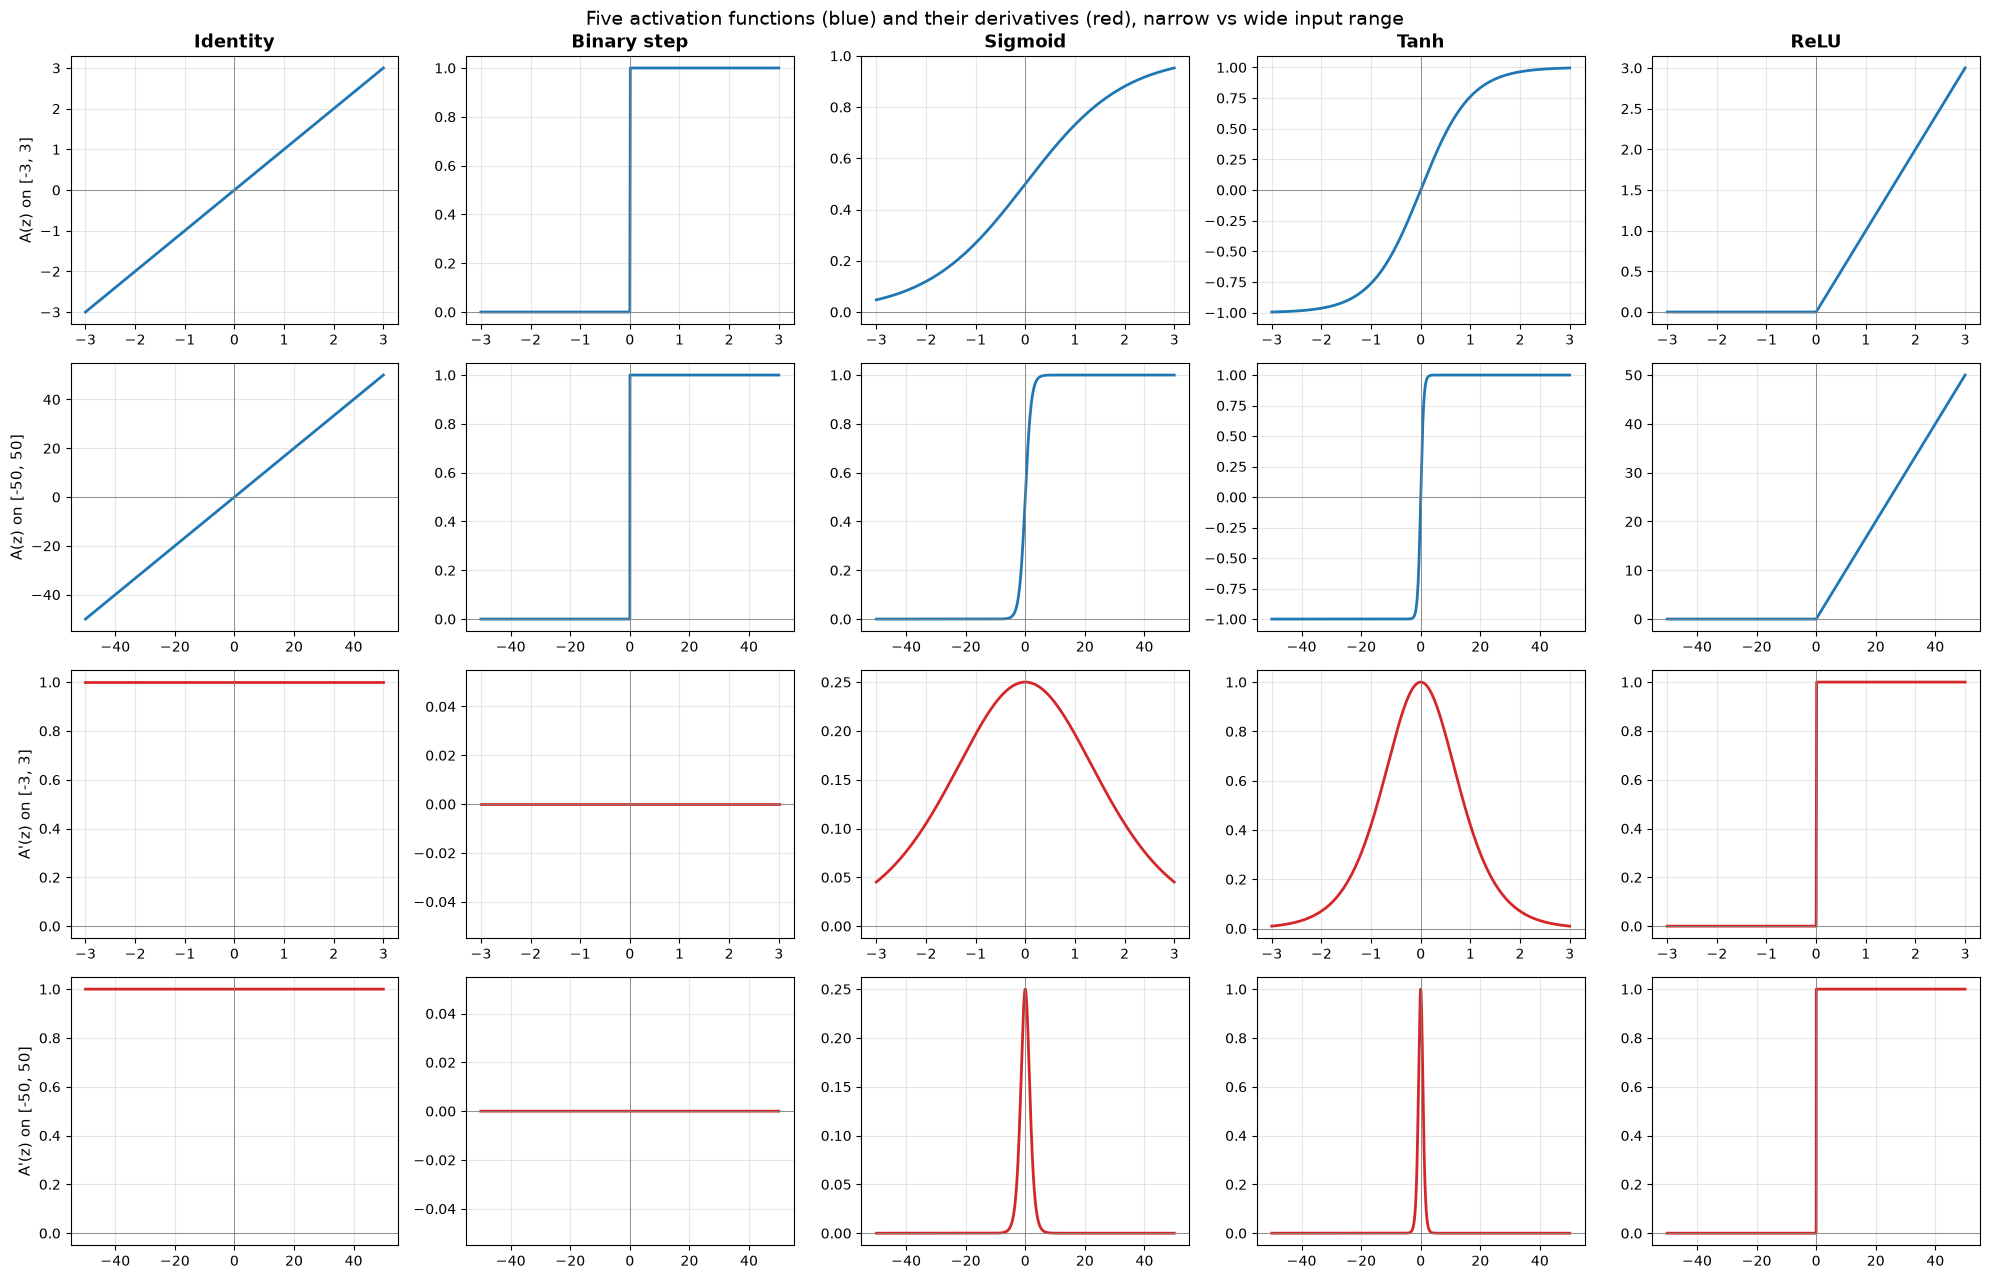

In [12]:
# --- Activation functions and their derivatives (NumPy, so we can plot them) ---
def identity(z):     return z
def d_identity(z):   return np.ones_like(z)

def step(z):         return np.where(z > 0, 1.0, 0.0)          # same z > 0 rule as the workshop
def d_step(z):       return np.zeros_like(z)                    # flat everywhere (undefined at 0)

def sigmoid(z):      return 1.0 / (1.0 + np.exp(-z))
def d_sigmoid(z):    s = sigmoid(z); return s * (1.0 - s)

def tanh(z):         return np.tanh(z)
def d_tanh(z):       return 1.0 - np.tanh(z) ** 2

def relu(z):         return np.maximum(0.0, z)
def d_relu(z):       return np.where(z > 0, 1.0, 0.0)

activations = {
    "Identity":    (identity, d_identity),
    "Binary step": (step,     d_step),
    "Sigmoid":     (sigmoid,  d_sigmoid),
    "Tanh":        (tanh,     d_tanh),
    "ReLU":        (relu,     d_relu),
}

z_narrow = np.linspace(-3, 3, 601)
z_wide   = np.linspace(-50, 50, 2001)

fig, axes = plt.subplots(4, 5, figsize=(20, 13), sharex="row")
rows = [("A(z) on [-3, 3]",   z_narrow, 0, "tab:blue"),
        ("A(z) on [-50, 50]", z_wide,   0, "tab:blue"),
        ("A'(z) on [-3, 3]",  z_narrow, 1, "tab:red"),
        ("A'(z) on [-50, 50]", z_wide,  1, "tab:red")]

for r, (label, z, which, colour) in enumerate(rows):
    for c, (name, fns) in enumerate(activations.items()):
        ax = axes[r, c]
        ax.plot(z, fns[which](z), color=colour, lw=2)
        ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
        ax.grid(alpha=0.3)
        if r == 0: ax.set_title(name, fontsize=13, fontweight="bold")
        if c == 0: ax.set_ylabel(label, fontsize=11)

fig.suptitle("Five activation functions (blue) and their derivatives (red), narrow vs wide input range",
             fontsize=14)
plt.tight_layout()
plt.show()

In [13]:
# --- Check the hand-written derivatives against both frameworks' automatic differentiation ---
z_np = z_narrow.astype(np.float32)

torch_fns = {"Identity": lambda t: t, "Sigmoid": torch.sigmoid, "Tanh": torch.tanh, "ReLU": torch.relu}
tf_fns    = {"Identity": tf.identity, "Sigmoid": tf.math.sigmoid, "Tanh": tf.math.tanh, "ReLU": tf.nn.relu}

print(f"{'Function':<10} | {'max |numpy - torch|':>20} | {'max |numpy - tf|':>17}")
print("-" * 54)
for name in torch_fns:
    # PyTorch: summing the outputs and calling backward() gives dA/dz at every point
    z_t = torch.tensor(z_np, requires_grad=True)
    torch_fns[name](z_t).sum().backward()
    grad_torch = z_t.grad.numpy()

    # TensorFlow: GradientTape records the forward pass, then tape.gradient differentiates it
    z_tf = tf.constant(z_np)
    with tf.GradientTape() as tape:
        tape.watch(z_tf)
        out = tf_fns[name](z_tf)
    grad_tf = tape.gradient(out, z_tf).numpy()

    ours = activations[name][1](z_np)
    err_t, err_tf = np.max(np.abs(ours - grad_torch)), np.max(np.abs(ours - grad_tf))
    assert err_t < 1e-5 and err_tf < 1e-5, f"{name}: derivative mismatch"
    print(f"{name:<10} | {err_t:>20.2e} | {err_tf:>17.2e}")

print("\nAll analytic derivatives match PyTorch autograd and TensorFlow GradientTape.")
print("(The binary step has no useful gradient, which is why it can't be trained with gradient descent.)")

# Size of the sigmoid and tanh gradients far from zero
for zv in [0, 3, 10, 50]:
    print(f"z = {zv:>2}:  sigmoid'(z) = {d_sigmoid(np.float64(zv)):.2e}   tanh'(z) = {d_tanh(np.float64(zv)):.2e}")

Function   |  max |numpy - torch| |  max |numpy - tf|
------------------------------------------------------
Identity   |             0.00e+00 |          0.00e+00
Sigmoid    |             5.22e-08 |          1.04e-07
Tanh       |             1.19e-07 |          2.38e-07
ReLU       |             0.00e+00 |          0.00e+00

All analytic derivatives match PyTorch autograd and TensorFlow GradientTape.
(The binary step has no useful gradient, which is why it can't be trained with gradient descent.)
z =  0:  sigmoid'(z) = 2.50e-01   tanh'(z) = 1.00e+00
z =  3:  sigmoid'(z) = 4.52e-02   tanh'(z) = 9.87e-03
z = 10:  sigmoid'(z) = 4.54e-05   tanh'(z) = 8.24e-09
z = 50:  sigmoid'(z) = 0.00e+00   tanh'(z) = 0.00e+00


#### What the two input ranges show

* **On $[-3, 3]$**, sigmoid and tanh look like smooth S-curves and their derivatives are clearly non-zero. In this region a small change in $z$ still changes the output, so the neuron can learn.
* **On $[-50, 50]$**, sigmoid and tanh look almost exactly like the **binary step**: they **saturate** at 0/1 (or −1/1) once $|z|$ is more than about 5. Their derivatives drop to almost nothing. The check above shows $\sigma'(10) \approx 4.5 \times 10^{-5}$, and at $z = 50$ the derivative is effectively zero. This is the **vanishing gradient** problem: a saturated neuron passes back almost no gradient, so its weights stop updating.
* **ReLU** never saturates for positive $z$ (its derivative stays 1), which is why it is the default for hidden layers. Its weakness is the flat zero region. A neuron whose $z$ is always negative gets zero gradient and stops learning (a "dead ReLU").
* **Identity** has a constant derivative of 1 but adds no non-linearity, so stacking identity layers is still just one linear layer.
* **Binary step** has a derivative of 0 everywhere it is defined. It works for hand-built logic gates (next section), but you cannot train it with gradient descent, which is why trained networks use sigmoid, tanh or ReLU instead.

### Verifying logic gates in both frameworks

A single-layer perceptron with a **step activation** can act as a logic gate. Below, `verify_gate(weights, bias, expected)`:

1. builds **every binary input combination** for the number of inputs (2 inputs → 4 rows, 3 inputs → 8 rows), in `itertools.product` order: `(0,0), (0,1), (1,0), (1,1)`;
2. computes the weighted sum $z = \mathbf{X}\mathbf{w} + b$ in **PyTorch** and, separately, in **TensorFlow**;
3. applies the step function ($1$ if $z > 0$, else $0$);
4. uses **`assert`** to check that both frameworks give the expected truth table and the same $z$ values;
5. prints the truth table and returns the $z$ values, which we use to explain inhibition.

If any row is wrong, the notebook stops with an `AssertionError` that names the row, so a mistake can't go unnoticed.

In [14]:
def verify_gate(weights, bias, expected, name="gate", input_names=None):
    """Check a step-activation perceptron against its expected truth table in PyTorch AND TensorFlow.

    weights  : list of floats, one per input
    bias     : float
    expected : list of 0/1 outputs, one per row of product([0, 1], repeat=len(weights))
    Returns the z values (NumPy array) so they can be inspected or plotted.
    """
    n = len(weights)
    combos = list(product([0, 1], repeat=n))
    assert len(expected) == len(combos), f"{name}: need {len(combos)} expected outputs, got {len(expected)}"
    X = np.array(combos, dtype=np.float32)
    input_names = input_names or [chr(ord("A") + i) for i in range(n)]

    # --- PyTorch: weighted sum, then step activation ---
    w_torch = torch.tensor(weights, dtype=torch.float32)
    z_torch = torch.matmul(torch.from_numpy(X), w_torch) + bias
    out_torch = (z_torch > 0).int().tolist()

    # --- TensorFlow: same computation ---
    w_tf = tf.constant(weights, dtype=tf.float32)
    z_tf = tf.linalg.matvec(tf.constant(X), w_tf) + bias
    out_tf = tf.cast(z_tf > 0, tf.int32).numpy().tolist()

    # --- Print the truth table ---
    header = " ".join(f"{s:>2}" for s in input_names)
    print(f"{name}   (weights={weights}, bias={bias})")
    print(f"{header} | {'z (torch)':>9} | {'z (tf)':>7} | out torch | out tf | expected")
    print("-" * (len(header) + 56))
    for row, zt, ztf, ot, otf, e in zip(combos, z_torch.tolist(), z_tf.numpy(), out_torch, out_tf, expected):
        flag = "" if ot == otf == e else "   <-- MISMATCH"
        print(f"{' '.join(f'{v:>2}' for v in row)} | {zt:>9.1f} | {ztf:>7.1f} | {ot:>9} | {otf:>6} | {e:>8}{flag}")

    # --- The checks ---
    assert np.allclose(z_torch.numpy(), z_tf.numpy()), f"{name}: PyTorch and TensorFlow disagree on z"
    for row, ot, otf, e in zip(combos, out_torch, out_tf, expected):
        assert ot == e,  f"{name}: PyTorch gives {ot} for input {row}, expected {e}"
        assert otf == e, f"{name}: TensorFlow gives {otf} for input {row}, expected {e}"
    print(f"✅ {name} passes in PyTorch and TensorFlow\n")
    return z_torch.numpy()

In [15]:
# Weights and biases are the ones from the workshop slides.
# Expected outputs follow product([0, 1], repeat=n) order: (0,0), (0,1), (1,0), (1,1).

z_identity = verify_gate([2.0], -1.0, [0, 1],                  name="Case 1: C = A")
z_and      = verify_gate([1.0, 1.0], -1.5, [0, 0, 0, 1],       name="Case 2: C = A AND B")
z_or       = verify_gate([1.0, 2.0], -0.5, [0, 1, 1, 1],       name="Case 3: C = A OR B")
z_inhibit  = verify_gate([1.0, -1.0], -0.5, [0, 0, 1, 0],      name="Case 4: C = A AND NOT B")

Case 1: C = A   (weights=[2.0], bias=-1.0)
 A | z (torch) |  z (tf) | out torch | out tf | expected
----------------------------------------------------------
 0 |      -1.0 |    -1.0 |         0 |      0 |        0
 1 |       1.0 |     1.0 |         1 |      1 |        1
✅ Case 1: C = A passes in PyTorch and TensorFlow

Case 2: C = A AND B   (weights=[1.0, 1.0], bias=-1.5)
 A  B | z (torch) |  z (tf) | out torch | out tf | expected
-------------------------------------------------------------
 0  0 |      -1.5 |    -1.5 |         0 |      0 |        0
 0  1 |      -0.5 |    -0.5 |         0 |      0 |        0
 1  0 |      -0.5 |    -0.5 |         0 |      0 |        0
 1  1 |       0.5 |     0.5 |         1 |      1 |        1
✅ Case 2: C = A AND B passes in PyTorch and TensorFlow

Case 3: C = A OR B   (weights=[1.0, 2.0], bias=-0.5)
 A  B | z (torch) |  z (tf) | out torch | out tf | expected
-------------------------------------------------------------
 0  0 |      -0.5 |    -0.5 | 

In [16]:
# Showing that the asserts work: give OR the AND gate's truth table on purpose.
try:
    verify_gate([1.0, 2.0], -0.5, [0, 0, 0, 1], name="OR weights checked against the AND table (deliberately wrong)")
except AssertionError as err:
    print(f"\n❌ AssertionError caught as intended: {err}")

OR weights checked against the AND table (deliberately wrong)   (weights=[1.0, 2.0], bias=-0.5)
 A  B | z (torch) |  z (tf) | out torch | out tf | expected
-------------------------------------------------------------
 0  0 |      -0.5 |    -0.5 |         0 |      0 |        0
 0  1 |       1.5 |     1.5 |         1 |      1 |        0   <-- MISMATCH
 1  0 |       0.5 |     0.5 |         1 |      1 |        0   <-- MISMATCH
 1  1 |       2.5 |     2.5 |         1 |      1 |        1

❌ AssertionError caught as intended: OR weights checked against the AND table (deliberately wrong): PyTorch gives 1 for input (0, 1), expected 0


**How each gate works** (read the $z$ column above):

* **C = A** ($w = 2, b = -1$): $A = 0 \Rightarrow z = -1$ (off); $A = 1 \Rightarrow z = 1$ (on). The output copies the input.
* **AND** ($w = [1, 1], b = -1.5$): one active input gives $z = -0.5$, which is not enough. Only both together reach $z = 0.5 > 0$. The bias sets the bar above what one input can reach alone.
* **OR** ($w = [1, 2], b = -0.5$): one active input is enough: $A$ alone gives $z = 0.5$, $B$ alone gives $z = 1.5$. The larger weight on $B$ means $B$ has more influence, but either input can fire the neuron.
* **A ∧ ¬B** ($w = [1, -1], b = -0.5$): explained in the next section.

In both frameworks the calculation is the same: a **dot product** (`torch.matmul` / `tf.linalg.matvec`), **plus the bias**, then a **threshold**. The two libraries only differ in syntax.

### How a negative weight inhibits activation

For **C = A ∧ ¬B** the weights are $w_A = +1$ (**excitatory**) and $w_B = -1$ (**inhibitory**), with $b = -0.5$:

$$
z = (+1)\,A + (-1)\,B - 0.5
$$

| A | B | Calculation | $z$ | C = step(z) | What happens |
|---|---|---|---|---|---|
| 0 | 0 | $0 - 0 - 0.5$ | $-0.5$ | 0 | Only the bias acts, so the neuron stays off |
| 0 | 1 | $0 - 1 - 0.5$ | $-1.5$ | 0 | B pushes $z$ further below zero |
| **1** | **0** | $1 - 0 - 0.5$ | **$+0.5$** | **1** | A alone gets over the threshold, so the neuron fires |
| 1 | 1 | $1 - 1 - 0.5$ | $-0.5$ | 0 | **B cancels A exactly**, pulling $z$ back to the "off" level |

Compare the rows where A = 1: switching B on drops $z$ from **+0.5 to −0.5**, a change of exactly $w_B = -1$. A negative weight **subtracts** from the evidence for firing, just as an inhibitory synapse in the brain lowers a neuron's membrane potential. Because $|w_B| = |w_A|$, B always cancels A completely, so **no combination with B = 1 can fire the neuron**. B works as a veto.

The bias matters too: with $b = -0.5$, A's +1 is only just enough to cross zero. If the bias were $+0.5$, the row A = 1, B = 1 would give $z = +0.5$ and the neuron would fire even with B on, so the inhibition would fail.

In [17]:
#  The correct weighted sum uses each input with its own weight: z = w[0]*A + w[1]*B + bias.

weights = [1.0, -1.0]   # A excites (+1), B inhibits (-1)
bias = -0.5
inputs = [(0, 0), (1, 0), (0, 1), (1, 1)]

def step_scalar(x):
    return 1 if x > 0 else 0

print("🔵 PyTorch")
for A, B in inputs:
    x = torch.tensor([A, B], dtype=torch.float32)
    w = torch.tensor(weights)
    z = torch.dot(w, x) + bias          # z = w[0]*A + w[1]*B + bias   (corrected comment)
    print(f"A={A}, B={B} → z={z.item():+.1f} → C={step_scalar(z.item())}")

print("\n🟢 TensorFlow")
for A, B in inputs:
    x = tf.constant([A, B], dtype=tf.float32)
    w = tf.constant(weights)
    z = tf.reduce_sum(w * x) + bias     # z = w[0]*A + w[1]*B + bias
    print(f"A={A}, B={B} → z={z.numpy():+.1f} → C={step_scalar(z.numpy())}")

🔵 PyTorch
A=0, B=0 → z=-0.5 → C=0
A=1, B=0 → z=+0.5 → C=1
A=0, B=1 → z=-1.5 → C=0
A=1, B=1 → z=-0.5 → C=0

🟢 TensorFlow
A=0, B=0 → z=-0.5 → C=0
A=1, B=0 → z=+0.5 → C=1
A=0, B=1 → z=-1.5 → C=0
A=1, B=1 → z=-0.5 → C=0


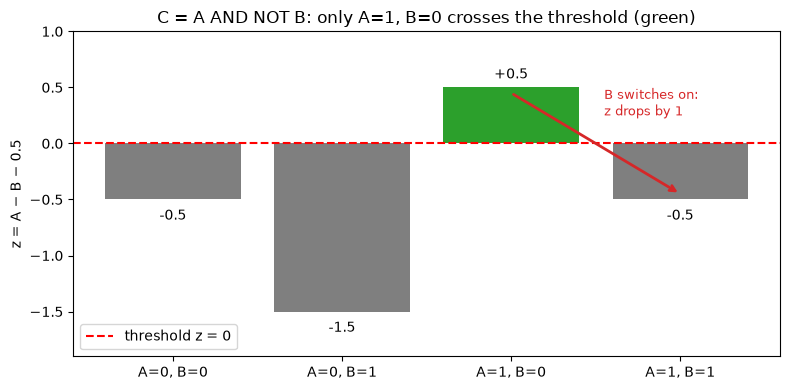

In [18]:
# Visualising inhibition: z for every input row, with the firing threshold at z = 0
labels = ["A=0, B=0", "A=0, B=1", "A=1, B=0", "A=1, B=1"]      # product() order, same as z_inhibit
colours = ["tab:green" if z > 0 else "tab:grey" for z in z_inhibit]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, z_inhibit, color=colours)
ax.axhline(0, color="red", ls="--", lw=1.5, label="threshold z = 0")
for bar, z in zip(bars, z_inhibit):
    ax.text(bar.get_x() + bar.get_width() / 2, z + (0.08 if z > 0 else -0.18), f"{z:+.1f}", ha="center")
ax.annotate("", xy=(3, -0.45), xytext=(2, 0.45),
            arrowprops=dict(arrowstyle="->", color="tab:red", lw=2))
ax.text(2.55, 0.25, "B switches on:\nz drops by 1", color="tab:red", fontsize=9)
ax.set_ylabel("z = A − B − 0.5"); ax.set_ylim(-1.9, 1.0)
ax.set_title("C = A AND NOT B: only A=1, B=0 crosses the threshold (green)")
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

### Movie challenge: our own weights

**Inputs** (1 = yes, 0 = no): $x_1$ = good weather, $x_2$ = have company, $x_3$ = cinema is nearby.

The workshop's version uses equal weights $[1, 1, 1]$ and $b = -2.5$, so **all three** must be yes. That is a plain 3-input AND. Our version weights the inputs **unequally** to model a more realistic decision:

$$
w = [\,3,\; 2,\; 1\,], \qquad b = -3.5, \qquad z = 3x_1 + 2x_2 + 1x_3 - 3.5
$$

* **Weather** has the biggest weight (3) and is required. Without it, the best possible score is $2 + 1 - 3.5 = -0.5$, which is below the threshold.
* Weather **alone** is not enough either: $3 - 3.5 = -0.5$.
* Weather **plus at least one** of company or proximity crosses the threshold: $3 + 1 - 3.5 = +0.5$ and $3 + 2 - 3.5 = +1.5$.

So this single neuron computes $x_1 \land (x_2 \lor x_3)$: *"I'll go if the weather is good **and** I either have company **or** the cinema is close."* We check all **8 input combinations** with `verify_gate` in both frameworks, then also pass $z$ through **sigmoid** to show how confident the neuron is, as in the Wonderland example.

In [19]:
movie_weights = [3.0, 2.0, 1.0]     # weather, company, proximity
movie_bias = -3.5
#                 000 001 010 011 100 101 110 111   (x1 x2 x3)
movie_expected = [0,  0,  0,  0,  0,  1,  1,  1]

z_movie = verify_gate(movie_weights, movie_bias, movie_expected,
                      name="Movie decision: weather AND (company OR proximity)",
                      input_names=["x1", "x2", "x3"])

Movie decision: weather AND (company OR proximity)   (weights=[3.0, 2.0, 1.0], bias=-3.5)
x1 x2 x3 | z (torch) |  z (tf) | out torch | out tf | expected
----------------------------------------------------------------
 0  0  0 |      -3.5 |    -3.5 |         0 |      0 |        0
 0  0  1 |      -2.5 |    -2.5 |         0 |      0 |        0
 0  1  0 |      -1.5 |    -1.5 |         0 |      0 |        0
 0  1  1 |      -0.5 |    -0.5 |         0 |      0 |        0
 1  0  0 |      -0.5 |    -0.5 |         0 |      0 |        0
 1  0  1 |       0.5 |     0.5 |         1 |      1 |        1
 1  1  0 |       1.5 |     1.5 |         1 |      1 |        1
 1  1  1 |       2.5 |     2.5 |         1 |      1 |        1
✅ Movie decision: weather AND (company OR proximity) passes in PyTorch and TensorFlow



In [20]:
# Same 8 rows with a sigmoid output in both frameworks, so we also see how confident the neuron is
X_movie = torch.tensor(list(product([0, 1], repeat=3)), dtype=torch.float32)
conf_torch = torch.sigmoid(X_movie @ torch.tensor(movie_weights) + movie_bias)
conf_tf = tf.math.sigmoid(tf.linalg.matvec(tf.constant(X_movie.numpy()), tf.constant(movie_weights)) + movie_bias)
assert np.allclose(conf_torch.numpy(), conf_tf.numpy(), atol=1e-6)

meaning = {(0,0,0): "stay home", (0,0,1): "close, but it's raining", (0,1,0): "friend, but it's raining",
           (0,1,1): "nearby + friend, still raining", (1,0,0): "nice weather, but alone & far",
           (1,0,1): "nice weather + nearby", (1,1,0): "nice weather + friend", (1,1,1): "everything lines up"}

print("weather company near |    z  | σ(z) torch | σ(z) tf | go? | scenario")
print("-" * 82)
for row, z, ct, ctf in zip(product([0, 1], repeat=3), z_movie, conf_torch.numpy(), conf_tf.numpy()):
    go = "YES" if z > 0 else "no"
    print(f"{row[0]:>7} {row[1]:>7} {row[2]:>4} | {z:+5.1f} | {ct:>10.3f} | {ctf:>7.3f} | {go:>3} | {meaning[row]}")

weather company near |    z  | σ(z) torch | σ(z) tf | go? | scenario
----------------------------------------------------------------------------------
      0       0    0 |  -3.5 |      0.029 |   0.029 |  no | stay home
      0       0    1 |  -2.5 |      0.076 |   0.076 |  no | close, but it's raining
      0       1    0 |  -1.5 |      0.182 |   0.182 |  no | friend, but it's raining
      0       1    1 |  -0.5 |      0.378 |   0.378 |  no | nearby + friend, still raining
      1       0    0 |  -0.5 |      0.378 |   0.378 |  no | nice weather, but alone & far
      1       0    1 |  +0.5 |      0.622 |   0.622 | YES | nice weather + nearby
      1       1    0 |  +1.5 |      0.818 |   0.818 | YES | nice weather + friend
      1       1    1 |  +2.5 |      0.924 |   0.924 | YES | everything lines up


### Talking point

> 💬 **"One neuron can express priorities, not just AND or OR."**
>
> With equal weights, a perceptron can only count yes-votes: either *all* of them (AND) or *any* of them (OR). By making the **weather weight (3) bigger than company (2) and proximity (1)**, and putting the bias at $-3.5$, our single neuron makes good weather **required but not sufficient**. It then needs at least one more reason to go. That's the rule $x_1 \land (x_2 \lor x_3)$, which neither a plain AND nor a plain OR can express.
>
> The sigmoid column adds a second point. The two cases with the lowest confidence of going, *"nice weather but alone & far"* and *"nearby + friend but raining"*, both sit at $z = -0.5$, with σ(z) ≈ 0.38. They are just under the boundary. **The bias is the knob that moves that boundary**: change it from −3.5 to −2.5 and "nice weather alone" becomes a yes. So does "nearby + friend, still raining" (also $z = +0.5$), which means weather would no longer be required. Weights decide *what matters*; the bias decides *how much is enough*.

## Decision Boundaries, XOR & TensorFlow Playground
*Author: Davisen*

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product

# The four binary input combinations, used by every section below
X = np.array([[0, 0], [1, 0], [0, 1], [1, 1]])

def step(z):
    """Step activation used throughout the workshop: a = 1 if z > 0, else 0."""
    return (np.asarray(z) > 0).astype(int)

def perceptron(X, w, b):
    """Return (z, a) for every row of X."""
    z = X @ np.asarray(w, dtype=float) + b
    return z, step(z)

def truth_table(name, w, b, X=X):
    z, a = perceptron(X, w, b)
    print(f"{name}:  w = {list(w)},  b = {b}")
    print("  x1 x2 |    z   | a")
    print("  ------+--------+---")
    for (x1, x2), zi, ai in zip(X, z, a):
        print(f"   {x1}  {x2} | {zi:6.2f} | {ai}")
    print()
    return a

# Colours: blue = fires (a = 1), orange = does not fire (a = 0).
# The marker shape also differs (filled circle vs. cross), so the plots
# don't rely on colour alone.
FIRE, NOFIRE = "#2a6fdb", "#e8833a"

def plot_boundary(ax, w, b, title, lim=(-0.5, 2.0), show_points=True,
                  show_normal=True, line_kw=None, shade=True, X=X, labels=None):
    """Shade the a=1 / a=0 regions of a 2-input step perceptron and draw z = 0."""
    w1, w2 = w
    g = np.linspace(*lim, 400)
    G1, G2 = np.meshgrid(g, g)
    Z = w1 * G1 + w2 * G2 + b
    if shade:
        ax.contourf(G1, G2, (Z > 0).astype(int), levels=[-0.5, 0.5, 1.5],
                    colors=[NOFIRE, FIRE], alpha=0.15)
    kw = dict(colors="k", linewidths=2)
    if line_kw:
        kw.update(line_kw)
    ax.contour(G1, G2, Z, levels=[0], **kw)
    if show_points:
        _, a = perceptron(X, w, b)
        for (x1, x2), ai in zip(X, a):
            if ai:
                ax.scatter(x1, x2, s=110, c=FIRE, edgecolors="white", linewidths=2, zorder=3)
            else:
                ax.scatter(x1, x2, s=110, c=NOFIRE, marker="X", edgecolors="white", linewidths=1, zorder=3)
            ax.annotate(f"a={ai}", (x1, x2), textcoords="offset points", xytext=(8, 6), fontsize=9)
    if show_normal:
        # The weight vector (w1, w2) is perpendicular to the boundary and points to the a=1 side
        p = -b * np.array([w1, w2]) / (w1**2 + w2**2)   # closest point on the line to the origin
        n = 0.35 * np.array([w1, w2]) / np.hypot(w1, w2)
        ax.annotate("", xy=p + n, xytext=p, arrowprops=dict(arrowstyle="->", color="k", lw=1.5))
        ax.text(*(p + 1.25 * n), "w", fontsize=10, ha="center", va="center")
    ax.axhline(0, color="0.7", lw=0.8); ax.axvline(0, color="0.7", lw=0.8)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title(title)
    return ax

### Plotting the decision boundary

The workshop's linear-classifier diagram uses a single neuron with weights $w_1 = w_2 = -2$, bias $b = 3$ and a step activation:

$$
z = -2x_1 - 2x_2 + 3, \qquad
a = \begin{cases} 1 & z > 0 \\ 0 & z \le 0 \end{cases}
$$

The **decision boundary** is the set of points where $z = 0$:

$$
-2x_1 - 2x_2 + 3 = 0 \;\;\Longrightarrow\;\; x_2 = -x_1 + 1.5
$$

Below we shade both regions (blue = $a = 1$, orange = $a = 0$), plot the four binary inputs, and print the truth table.

Slide neuron  z = -2x1 - 2x2 + 3:  w = [-2, -2],  b = 3
  x1 x2 |    z   | a
  ------+--------+---
   0  0 |   3.00 | 1
   1  0 |   1.00 | 1
   0  1 |   1.00 | 1
   1  1 |  -1.00 | 0

Matches NAND (NOT (x1 AND x2))? True


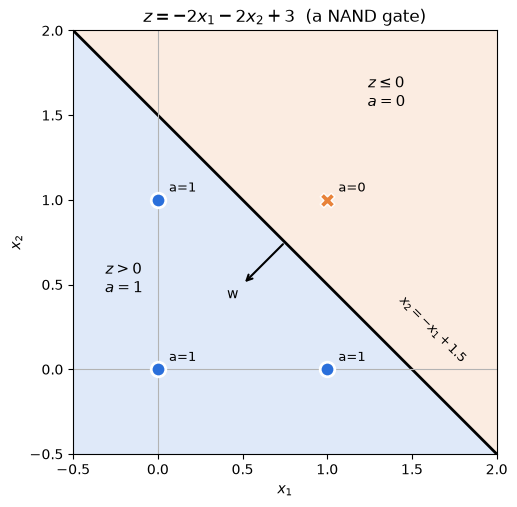

In [22]:
w_nand, b_nand = [-2, -2], 3

a_nand = truth_table("Slide neuron  z = -2x1 - 2x2 + 3", w_nand, b_nand)
nand_expected = 1 - (X[:, 0] & X[:, 1])
print("Matches NAND (NOT (x1 AND x2))?", np.array_equal(a_nand, nand_expected))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
plot_boundary(ax, w_nand, b_nand, "$z = -2x_1 - 2x_2 + 3$  (a NAND gate)")
ax.text(1.35, 1.55, "$z \\leq 0$\n$a = 0$", fontsize=11, ha="center")
ax.text(-0.2, 0.45, "$z > 0$\n$a = 1$", fontsize=11, ha="center")
ax.text(1.62, 0.02, "$x_2 = -x_1 + 1.5$", fontsize=9, rotation=-45, ha="center", va="bottom")
plt.show()

**What the plot shows**

| $x_1$ | $x_2$ | $z$ | $a$ |
|---|---|---|---|
| 0 | 0 | $3$ | 1 |
| 1 | 0 | $1$ | 1 |
| 0 | 1 | $1$ | 1 |
| 1 | 1 | $-1$ | 0 |

The neuron outputs 0 **only** when both inputs are 1. That is the truth table of **NAND** ($\lnot(x_1 \land x_2)$), which the code confirms.

- Three of the points lie on the origin side of the line, where $z > 0$, so they fire. Only $(1,1)$ is on the far side.
- The arrow labelled **w** is the weight vector $(w_1, w_2) = (-2, -2)$. It is always perpendicular to the boundary and points towards the side that fires. Here it points down and to the left, towards the origin.
- NAND is *functionally complete*: any logic circuit can be built from NAND gates alone. We use this in the XOR section below.

### How weights and bias move the line

Solving $w_1x_1 + w_2x_2 + b = 0$ for $x_2$ (assuming $w_2 \neq 0$) gives the line in slope–intercept form:

$$
x_2 = \underbrace{-\frac{w_1}{w_2}}_{\text{slope}}\,x_1 \;\underbrace{-\;\frac{b}{w_2}}_{x_2\text{-intercept}}
$$

The line also crosses the $x_1$-axis at $x_1 = -b/w_1$.

- The **slope depends only on the weights**, so changing a weight **rotates** the line.
- The **bias appears only in the intercepts**, so changing the bias **shifts the line in parallel** without changing its slope.

We test both, starting from the NAND neuron $(w_1, w_2, b) = (-2, -2, 3)$:
1. Change **one weight**: $w_1 = -2 \to -4$, keeping $w_2$ and $b$ fixed.
2. Change **the bias**: $b = 3 \to 1$ and $b = 3 \to 5$, keeping the weights fixed.

experiment        w1  w2   b |  slope  x2-int  x1-int | outputs (00,10,01,11) -> gate
-----------------------------------------------------------------------------------------------


baseline  w1=-2   -2  -2   3 |  -1.00    1.50    1.50 | [1 1 1 0] -> NAND
w1 = -4           -4  -2   3 |  -2.00    1.50    0.75 | [1 0 1 0] -> NOT x1
b = 1             -2  -2   1 |  -1.00    0.50    0.50 | [1 0 0 0] -> NOR
baseline  b=3     -2  -2   3 |  -1.00    1.50    1.50 | [1 1 1 0] -> NAND
b = 5             -2  -2   5 |  -1.00    2.50    2.50 | [1 1 1 1] -> always 1


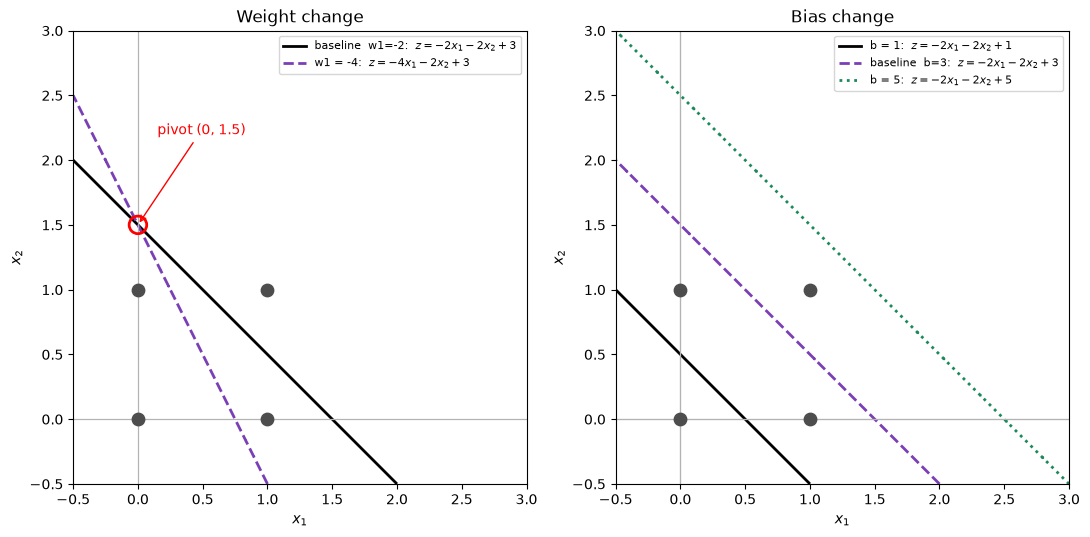

In [23]:
def line_info(w, b):
    w1, w2 = w
    return -w1 / w2, -b / w2, -b / w1      # slope, x2-intercept, x1-intercept

def gate_name(a):
    names = {(1,1,1,0): "NAND", (0,0,0,1): "AND", (0,1,1,1): "OR", (1,0,0,0): "NOR",
             (1,0,1,0): "NOT x1", (1,1,0,0): "NOT x2", (1,1,1,1): "always 1",
             (0,0,0,0): "always 0", (0,1,0,0): "x1 AND NOT x2", (0,1,1,0): "XOR"}
    return names.get(tuple(int(v) for v in a), "other")

experiments = {
    "Weight change": [((-2, -2), 3, "baseline  w1=-2"), ((-4, -2), 3, "w1 = -4")],
    "Bias change":   [((-2, -2), 1, "b = 1"), ((-2, -2), 3, "baseline  b=3"), ((-2, -2), 5, "b = 5")],
}

print(f"{'experiment':<16}{'w1':>4}{'w2':>4}{'b':>4} | {'slope':>6} {'x2-int':>7} {'x1-int':>7} | outputs (00,10,01,11) -> gate")
print("-" * 95)
for group, runs in experiments.items():
    for w, b, label in runs:
        s, i2, i1 = line_info(w, b)
        _, a = perceptron(X, w, b)
        print(f"{label:<16}{w[0]:>4}{w[1]:>4}{b:>4} | {s:>6.2f} {i2:>7.2f} {i1:>7.2f} | {a} -> {gate_name(a)}")

styles = ["-", "--", ":"]
colours = ["k", "#7b3fb5", "#1b8a5a"]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, (group, runs) in zip(axes, experiments.items()):
    for k, (w, b, label) in enumerate(runs):
        plot_boundary(ax, w, b, group, lim=(-0.5, 3.0), shade=False, show_normal=False,
                      show_points=False, line_kw=dict(colors=colours[k], linestyles=styles[k]))
        ax.plot([], [], color=colours[k], ls=styles[k], lw=2, label=f"{label}:  $z = {w[0]}x_1 {w[1]:+d}x_2 {b:+d}$")
    ax.scatter(X[:, 0], X[:, 1], s=80, c="0.3", zorder=3)
    ax.legend(loc="upper right", fontsize=8)
axes[0].scatter([0], [1.5], s=160, facecolors="none", edgecolors="r", lw=2, zorder=4)
axes[0].annotate("pivot (0, 1.5)", (0, 1.5), xytext=(0.15, 2.2), arrowprops=dict(arrowstyle="->", color="r"), color="r")
plt.tight_layout()
plt.show()

**Explanation (these numbers match the table printed above)**

**Changing one weight rotates the line.** With $w_1: -2 \to -4$:

$$
\text{slope} = -\frac{w_1}{w_2} = -\frac{-4}{-2} = -2 \quad(\text{was } -1), \qquad
x_2\text{-intercept} = -\frac{b}{w_2} = -\frac{3}{-2} = 1.5 \quad(\text{unchanged})
$$

The $x_2$-intercept does not depend on $w_1$, so the line **pivots about $(0, 1.5)$** and becomes steeper. Its $x_1$-intercept moves from $1.5$ to $-b/w_1 = 0.75$. A larger $|w_1|$ means $x_1$ has more influence on $z$, so the boundary tilts until it lies more across the $x_1$ direction. The point $(1,0)$ now gives $z = -4 + 3 = -1$, so it crosses to the non-firing side. The neuron's behaviour changes from **NAND** to **NOT $x_1$**.

**Changing the bias shifts the line in parallel.** The slope stays at $-1$ for every $b$, but the intercept $-b/w_2 = b/2$ changes:

| $b$ | line | gate |
|---|---|---|
| 1 | $x_2 = -x_1 + 0.5$ | **NOR**: only $(0,0)$ fires |
| 3 | $x_2 = -x_1 + 1.5$ | **NAND** (baseline) |
| 5 | $x_2 = -x_1 + 2.5$ | **always 1**: all four points fire |

The bias sets the neuron's **threshold**. Here $w_2 < 0$, so raising $b$ moves the line *away* from the origin and enlarges the firing region; lowering it does the opposite. With the **same weights**, the bias alone is enough to switch the neuron between three different logic functions.

> Side note: multiplying $w_1$, $w_2$ **and** $b$ by the same positive constant leaves the line (and every step-activation output) unchanged. Multiplying them all by $-1$ keeps the line but swaps which side fires. The next section shows this with AND and NAND.

### Decision boundaries of the workshop's logic gates

Now we use the same plotting function on the three gates from the workshop notebook, with the weights and biases exactly as given there:

| Gate | $w_1$ (A) | $w_2$ (B) | $b$ | Boundary $x_2 = -\frac{w_1}{w_2}x_1 - \frac{b}{w_2}$ |
|---|---|---|---|---|
| AND | 1 | 1 | −1.5 | $x_2 = -x_1 + 1.5$ |
| OR | 1 | 2 | −0.5 | $x_2 = -0.5\,x_1 + 0.25$ |
| A ∧ ¬B | 1 | −1 | −0.5 | $x_2 = x_1 - 0.5$ |

AND:  w = [1, 1],  b = -1.5
  x1 x2 |    z   | a
  ------+--------+---
   0  0 |  -1.50 | 0
   1  0 |  -0.50 | 0
   0  1 |  -0.50 | 0
   1  1 |   0.50 | 1

OR:  w = [1, 2],  b = -0.5
  x1 x2 |    z   | a
  ------+--------+---
   0  0 |  -0.50 | 0
   1  0 |   0.50 | 1
   0  1 |   1.50 | 1
   1  1 |   2.50 | 1

A AND NOT B:  w = [1, -1],  b = -0.5
  x1 x2 |    z   | a
  ------+--------+---
   0  0 |  -0.50 | 0
   1  0 |   0.50 | 1
   0  1 |  -1.50 | 0
   1  1 |  -0.50 | 0

All three gates reproduce their truth tables.


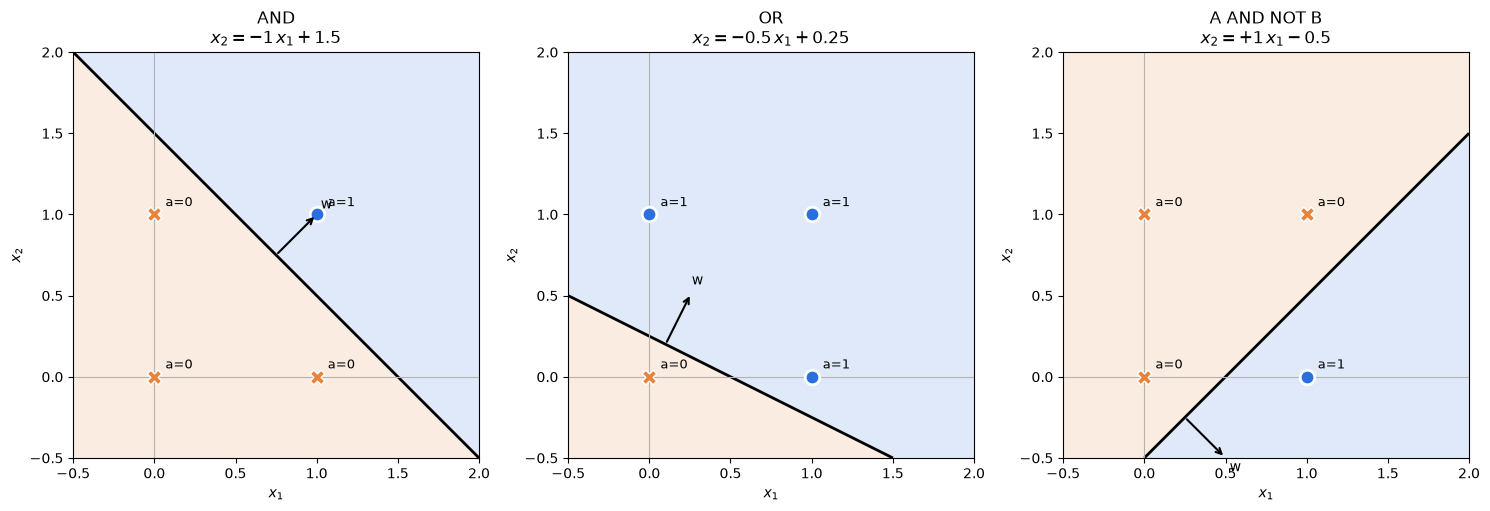

In [24]:
gates = {
    "AND":     ([1, 1],  -1.5, X[:, 0] & X[:, 1]),
    "OR":      ([1, 2],  -0.5, X[:, 0] | X[:, 1]),
    "A AND NOT B": ([1, -1], -0.5, X[:, 0] & (1 - X[:, 1])),
}

for name, (w, b, expected) in gates.items():
    a = truth_table(name, w, b)
    assert np.array_equal(a, expected), f"{name} does not match its truth table!"
print("All three gates reproduce their truth tables.")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, (w, b, _)) in zip(axes, gates.items()):
    s, i2, _ = line_info(w, b)
    plot_boundary(ax, w, b, f"{name}\n$x_2 = {s:+.2g}\\,x_1 {i2:+.2g}$")
plt.tight_layout()
plt.show()

**Observations**

- **AND vs. NAND.** AND $(1, 1, -1.5)$ is exactly $-\tfrac12 \times$ NAND $(-2, -2, 3)$. Both gates therefore have **the same line**, $x_2 = -x_1 + 1.5$, but the weight vector points the opposite way. AND fires *above* the line (only $(1,1)$) and NAND fires *below* it.
- **OR.** The bias $-0.5$ puts the line very close to the origin, so a single active input is enough to cross it. Because $w_2 = 2 > w_1 = 1$, the slope is only $-0.5$: the line is flatter, which shows that B has more influence than A.
- **A ∧ ¬B.** The negative weight on B gives the line a **positive** slope $(+1)$. The firing region is the lower-right triangle, *below* the line. Increasing $x_2$ moves you away from firing, which is the geometric meaning of **inhibition**. Only $(1,0)$ is inside that region.
- In every plot, the arrow **w** points into the blue (firing) region. Which side counts as "above" changes from gate to gate; the direction of **w** is what decides which side fires.

### Why a single perceptron cannot learn XOR

XOR outputs 1 when exactly one input is 1:

| $x_1$ | $x_2$ | XOR |
|---|---|---|
| 0 | 0 | 0 |
| 1 | 0 | 1 |
| 0 | 1 | 1 |
| 1 | 1 | 0 |

The two classes sit on **opposite diagonals** of the square. Any straight line that puts $(1,0)$ and $(0,1)$ on one side also puts at least one of $(0,0)$ or $(1,1)$ on that side. We show this in three ways: a proof, a training experiment and a brute-force search.

**1. Algebraic proof.** A single perceptron would need $(w_1, w_2, b)$ such that

$$
\begin{aligned}
(0,0)\to 0:&\quad b \le 0 \\
(1,0)\to 1:&\quad w_1 + b > 0 \\
(0,1)\to 1:&\quad w_2 + b > 0 \\
(1,1)\to 0:&\quad w_1 + w_2 + b \le 0
\end{aligned}
$$

Adding the two middle inequalities gives $w_1 + w_2 + 2b > 0$, i.e. $w_1 + w_2 + b > -b$. From the first line $-b \ge 0$, so $w_1 + w_2 + b > 0$. This contradicts the last line. **No weights and bias exist**: XOR is not linearly separable.

AND: first epoch with 0 errors = 9, final w = [0.16 0.23], b = -0.30
XOR: min errors in any epoch = 2, errors in last 10 epochs = [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]

Grid search over 1,030,301 (w1, w2, b) combinations in [-5, 5]:
  AND   solutions found:  21,563
  OR    solutions found:  44,775
  NAND  solutions found:  21,421
  XOR   solutions found:       0


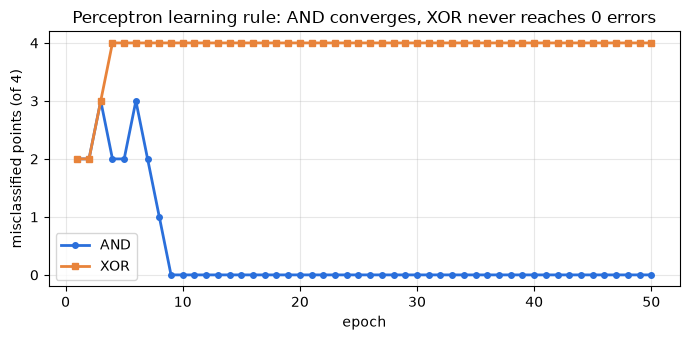

In [25]:
# 2. Training experiment: Rosenblatt's perceptron learning rule
#    w <- w + eta * (y - a) * x,   b <- b + eta * (y - a)
def train_perceptron(X, y, epochs=50, eta=0.1, seed=0):
    rng = np.random.default_rng(seed)
    w, b = rng.normal(0, 0.5, 2), 0.0
    errors = []
    for _ in range(epochs):
        n_err = 0
        for xi, yi in zip(X, y):
            a = int(xi @ w + b > 0)
            w += eta * (yi - a) * xi
            b += eta * (yi - a)
            n_err += int(a != yi)
        errors.append(n_err)
    return w, b, errors

y_and = X[:, 0] & X[:, 1]
y_xor = X[:, 0] ^ X[:, 1]

w_a, b_a, err_and = train_perceptron(X, y_and)
w_x, b_x, err_xor = train_perceptron(X, y_xor)

first_zero = err_and.index(0) + 1 if 0 in err_and else None
print(f"AND: first epoch with 0 errors = {first_zero}, final w = {np.round(w_a, 2)}, b = {b_a:.2f}")
print(f"XOR: min errors in any epoch = {min(err_xor)}, errors in last 10 epochs = {err_xor[-10:]}")

# 3. Brute-force search over a grid of weights and biases
vals = np.linspace(-5, 5, 101)                     # step 0.1 -> 101^3 = 1,030,301 neurons
W1, W2, B = np.meshgrid(vals, vals, vals, indexing="ij")
params = np.stack([W1.ravel(), W2.ravel(), B.ravel()], axis=1)
outs = (params[:, :2] @ X.T + params[:, 2:3] > 0).astype(int)  # shape (n_params, 4)
print(f"\nGrid search over {len(params):,} (w1, w2, b) combinations in [-5, 5]:")
for name, target in [("AND", y_and), ("OR", X[:, 0] | X[:, 1]), ("NAND", 1 - y_and), ("XOR", y_xor)]:
    n = int((outs == target).all(axis=1).sum())
    print(f"  {name:<5} solutions found: {n:>7,}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(1, 51), err_and, marker="o", ms=4, lw=2, color=FIRE, label="AND")
ax.plot(range(1, 51), err_xor, marker="s", ms=4, lw=2, color=NOFIRE, label="XOR")
ax.set_xlabel("epoch"); ax.set_ylabel("misclassified points (of 4)")
ax.set_yticks(range(5)); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Perceptron learning rule: AND converges, XOR never reaches 0 errors")
plt.tight_layout(); plt.show()

**Results**

- **Training:** on AND, the perceptron learning rule reaches 0 errors within a few epochs. The *perceptron convergence theorem* guarantees this for any linearly separable data. On XOR the error count **never drops to 0**: the line keeps moving back and forth, because fixing one point always misclassifies another.
- **Grid search:** more than a million weight/bias combinations produce thousands of valid AND, OR and NAND neurons, but **zero** XOR neurons. This agrees with the proof.

So the limitation is not about training or about choosing better numbers. A single perceptron can only draw **one straight line**, and XOR needs a region that no single line can produce.

There are two standard solutions, shown below:
1. **Change the input:** add a non-linear feature $x_3 = x_1 x_2$.
2. **Change the network:** add a hidden layer, so two lines are combined.

Solution 1: z = x1 + x2 - 2*x1*x2 - 0.5
  x1=0 x2=0 x1x2=0 -> z=-0.5 -> a=0
  x1=1 x2=0 x1x2=0 -> z=+0.5 -> a=1
  x1=0 x2=1 x1x2=0 -> z=+0.5 -> a=1
  x1=1 x2=1 x1x2=1 -> z=-0.5 -> a=0

Solution 2: XOR = AND( OR(x1,x2), NAND(x1,x2) )
  x1 x2 | h1=OR h2=NAND | z_out | y
   0  0 |   0     1     | -0.5  | 0
   1  0 |   1     1     | +0.5  | 1
   0  1 |   1     1     | +0.5  | 1
   1  1 |   1     0     | -0.5  | 0

Both solutions reproduce XOR exactly.


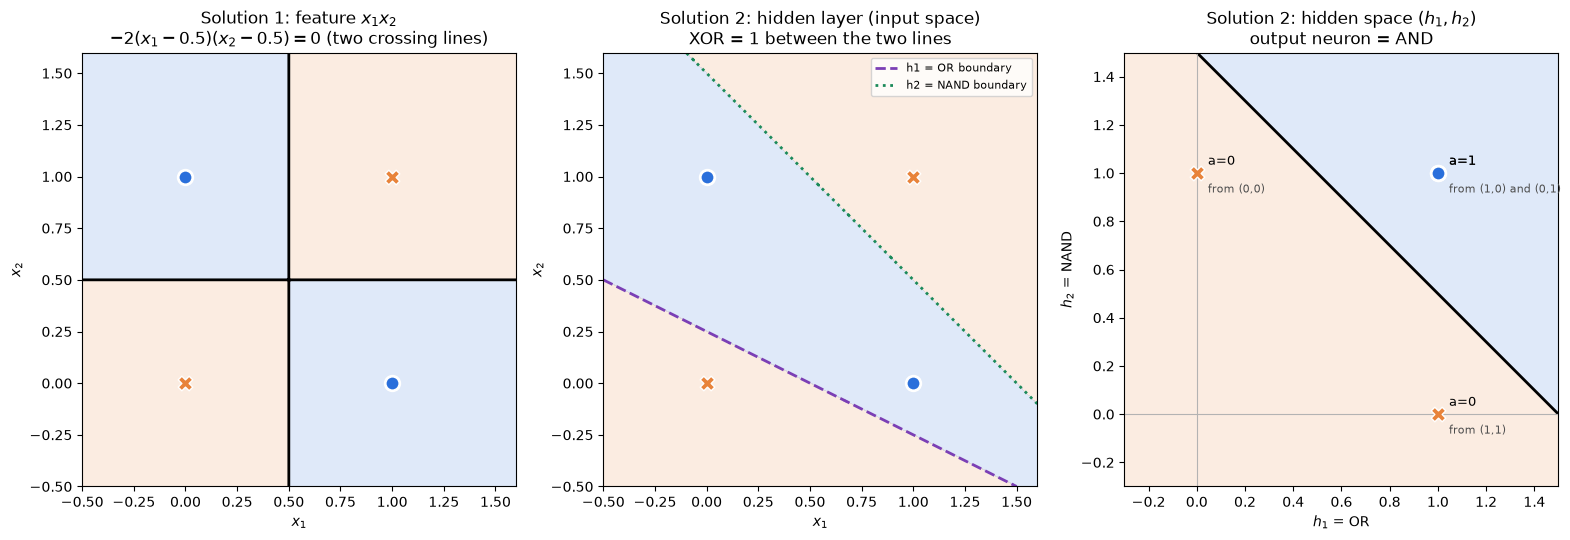

In [26]:
# --- Solution 1: add the feature x1*x2 (still ONE perceptron, now with 3 inputs) ---
w_feat, b_feat = np.array([1, 1, -2]), -0.5
X3 = np.column_stack([X, X[:, 0] * X[:, 1]])
z3, a3 = perceptron(X3, w_feat, b_feat)
print("Solution 1: z = x1 + x2 - 2*x1*x2 - 0.5")
for (x1, x2, x12), zi, ai in zip(X3, z3, a3):
    print(f"  x1={x1} x2={x2} x1x2={x12} -> z={zi:+.1f} -> a={ai}")
assert np.array_equal(a3, y_xor)

# --- Solution 2: two layers, built from gates we already have ---
#   h1 = OR(x1, x2)      workshop OR neuron   (w=[1, 2],  b=-0.5)
#   h2 = NAND(x1, x2)    slide neuron         (w=[-2,-2], b=3)
#   y  = AND(h1, h2)     workshop AND neuron  (w=[1, 1],  b=-1.5)
_, h1 = perceptron(X, [1, 2], -0.5)
_, h2 = perceptron(X, [-2, -2], 3)
H = np.column_stack([h1, h2])
z_out, y_out = perceptron(H, [1, 1], -1.5)
print("\nSolution 2: XOR = AND( OR(x1,x2), NAND(x1,x2) )")
print("  x1 x2 | h1=OR h2=NAND | z_out | y")
for (x1, x2), hh1, hh2, zo, yo in zip(X, h1, h2, z_out, y_out):
    print(f"   {x1}  {x2} |   {hh1}     {hh2}     | {zo:+.1f}  | {yo}")
assert np.array_equal(y_out, y_xor)
print("\nBoth solutions reproduce XOR exactly.")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
lim = (-0.5, 1.6)
g = np.linspace(*lim, 400); G1, G2 = np.meshgrid(g, g)

# (a) feature solution: in the original (x1, x2) space the boundary is two crossing lines
Zf = G1 + G2 - 2 * G1 * G2 - 0.5
axes[0].contourf(G1, G2, (Zf > 0).astype(int), levels=[-0.5, 0.5, 1.5], colors=[NOFIRE, FIRE], alpha=0.15)
axes[0].contour(G1, G2, Zf, levels=[0], colors="k", linewidths=2)
axes[0].set_title("Solution 1: feature $x_1x_2$\n$-2(x_1 - 0.5)(x_2 - 0.5) = 0$ (two crossing lines)")

# (b) two-layer solution: two hidden lines, XOR = the band between them
Z1 = 1 * G1 + 2 * G2 - 0.5
Z2 = -2 * G1 - 2 * G2 + 3
band = ((Z1 > 0) & (Z2 > 0)).astype(int)
axes[1].contourf(G1, G2, band, levels=[-0.5, 0.5, 1.5], colors=[NOFIRE, FIRE], alpha=0.15)
axes[1].contour(G1, G2, Z1, levels=[0], colors="#7b3fb5", linewidths=2, linestyles="--")
axes[1].contour(G1, G2, Z2, levels=[0], colors="#1b8a5a", linewidths=2, linestyles=":")
axes[1].plot([], [], "--", color="#7b3fb5", lw=2, label="h1 = OR boundary")
axes[1].plot([], [], ":", color="#1b8a5a", lw=2, label="h2 = NAND boundary")
axes[1].legend(loc="upper right", fontsize=8)
axes[1].set_title("Solution 2: hidden layer (input space)\nXOR = 1 between the two lines")

for ax in axes[:2]:
    for (x1, x2), yi in zip(X, y_xor):
        if yi: ax.scatter(x1, x2, s=110, c=FIRE, edgecolors="white", lw=2, zorder=3)
        else:  ax.scatter(x1, x2, s=110, c=NOFIRE, marker="X", edgecolors="white", lw=1, zorder=3)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")

# (c) the hidden layer re-maps the points so that ONE line (AND) now separates them
plot_boundary(axes[2], [1, 1], -1.5, "Solution 2: hidden space $(h_1, h_2)$\noutput neuron = AND",
              lim=(-0.3, 1.5), X=H, show_normal=False)
for txt, (hh1, hh2) in [("from (0,0)", (0, 1)), ("from (1,0) and (0,1)", (1, 1)), ("from (1,1)", (1, 0))]:
    axes[2].annotate(txt, (hh1, hh2), textcoords="offset points", xytext=(8, -14), fontsize=8, color="0.3")
axes[2].set_xlabel("$h_1$ = OR"); axes[2].set_ylabel("$h_2$ = NAND")
plt.tight_layout(); plt.show()

**How the two solutions work**

**Solution 1: the feature $x_1x_2$.** With the extra input $x_3 = x_1x_2$, the single neuron

$$z = x_1 + x_2 - 2x_1x_2 - 0.5$$

solves XOR. The term $-2x_1x_2$ only matters at $(1,1)$, where it cancels the $+2$ from the other two inputs. In 3-D space $(x_1, x_2, x_1x_2)$ the boundary is still a flat **plane**. Projected back onto $(x_1, x_2)$, it is no longer one line. Because $x_1 + x_2 - 2x_1x_2 - 0.5 = -2(x_1 - 0.5)(x_2 - 0.5)$, the boundary is the pair of crossing lines $x_1 = 0.5$ and $x_2 = 0.5$, and opposite quadrants share a class (left plot). The perceptron is still linear; we made the *data* linearly separable by choosing a better representation.

**Solution 2: a hidden layer.** XOR is "at least one input is on (OR) **and** not both are on (NAND)":

$$\text{XOR}(x_1, x_2) = \text{AND}\big(\text{OR}(x_1, x_2),\; \text{NAND}(x_1, x_2)\big)$$

- The middle plot shows the two hidden neurons as two lines in input space. XOR fires in the **band between them**, a region one line cannot create.
- The right plot shows the same four points in *hidden space* $(h_1, h_2)$. Both $(1,0)$ and $(0,1)$ map to $(1,1)$. $(0,0)$ maps to $(0,1)$ and $(1,1)$ maps to $(1,0)$. In this space the AND line separates them. The hidden layer **re-maps the inputs until they become linearly separable**, which is the basic reason deep networks work.

**Link to the class notes.** The *Deep Learning Fundamentals* slides make the same point with the Prostate Cancer example. With no hidden layer, the single sigmoid "S" curve "does not work well for this sample data". Once a hidden layer is added, the network can produce a non-linear curve that fits the data. XOR is the smallest example of that idea.

### Correction: which side of the line fires?

The workshop notebook's explanation of the yellow-line diagram says:

> 🟡 **Above the line** → $z > 0$ → $a = 1$
> ⚫ **Below or on the line** → $z \leq 0$ → $a = 0$

**This is reversed.** The diagram itself shades the region **above** the line and labels it "$z \le 0,\ a = 0$", and the maths agrees with the diagram:

- $(0, 0)$ lies **below** the line $x_2 = -x_1 + 1.5$ and gives $z = 3 > 0$, so it **fires** ($a = 1$).
- $(1, 1)$ lies **above** the line and gives $z = -1 \le 0$, so it does **not** fire ($a = 0$).

**Corrected statement**

- **Below the line** (the origin side) → $z > 0$ → $a = 1$
- **On or above the line** → $z \le 0$ → $a = 0$

**General rule:** for $x_2$ above the line, $z$ has the sign of $w_2$. If $w_2 < 0$ (as here) the region *above* gives $z < 0$; if $w_2 > 0$ (as in AND and OR) the region *above* fires. More simply, **the side that fires is the side the weight vector $\mathbf{w}$ points to.** The cell below checks this numerically.

In [27]:
def side(x, w, b):
    """Is point x above, on or below the boundary line (in the x2 direction)?"""
    w1, w2 = w
    line_x2 = -(w1 / w2) * x[0] - b / w2
    return "above" if x[1] > line_x2 + 1e-12 else ("below" if x[1] < line_x2 - 1e-12 else "on")

test_points = np.array([[0, 0], [1, 0], [0, 1], [1, 1], [0.75, 0.75], [2, 2], [-0.5, -0.5]])

for name, w, b in [("NAND slide neuron (w2 < 0)", [-2, -2], 3), ("AND gate (w2 > 0)", [1, 1], -1.5)]:
    z, a = perceptron(test_points, w, b)
    print(name)
    print("   point        | side of line |    z   | a")
    for p, zi, ai in zip(test_points, z, a):
        print(f"   ({p[0]:5.2f},{p[1]:5.2f}) | {side(p, w, b):>12} | {zi:6.2f} | {ai}")
    fired_sides = {side(p, w, b) for p, ai in zip(test_points, a) if ai == 1}
    print(f"   -> points that fire are all: {fired_sides}\n")

NAND slide neuron (w2 < 0)
   point        | side of line |    z   | a
   ( 0.00, 0.00) |        below |   3.00 | 1
   ( 1.00, 0.00) |        below |   1.00 | 1
   ( 0.00, 1.00) |        below |   1.00 | 1
   ( 1.00, 1.00) |        above |  -1.00 | 0
   ( 0.75, 0.75) |           on |   0.00 | 0
   ( 2.00, 2.00) |        above |  -5.00 | 0
   (-0.50,-0.50) |        below |   5.00 | 1
   -> points that fire are all: {'below'}

AND gate (w2 > 0)
   point        | side of line |    z   | a
   ( 0.00, 0.00) |        below |  -1.50 | 0
   ( 1.00, 0.00) |        below |  -0.50 | 0
   ( 0.00, 1.00) |        below |  -0.50 | 0
   ( 1.00, 1.00) |        above |   0.50 | 1
   ( 0.75, 0.75) |           on |   0.00 | 0
   ( 2.00, 2.00) |        above |   2.50 | 1
   (-0.50,-0.50) |        below |  -2.50 | 0
   -> points that fire are all: {'above'}



For the slide neuron, every firing point is **below** the line, and the point $(0.75, 0.75)$, which lies exactly on the line, gives $z = 0 \Rightarrow a = 0$. This confirms the corrected statement. The AND gate fires on the *opposite* side (above), so "above" or "below" on its own does not tell you which side fires. You need the sign of $w_2$, or the direction of $\mathbf{w}$.

### TensorFlow Playground observations

We used [TensorFlow Playground](https://playground.tensorflow.org) to test the XOR results above with real training. All runs used the **XOR** dataset ("exclusive or", the 4-quadrant pattern), the **tanh** activation, learning rate **0.03**, noise 0 and a 50% train/test split. The three experiments, with their configured links, were:

| # | Setup | Link |
|---|---|---|
| A | Inputs $X_1, X_2$ only, **no hidden layer** | [open](https://playground.tensorflow.org/#activation=tanh&batchSize=10&dataset=xor&learningRate=0.03&regularizationRate=0&noise=0&networkShape=&seed=0.12345&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&problem=classification&discretize=false) |
| B | Inputs $X_1, X_2$, **one hidden layer with 4 neurons** | [open](https://playground.tensorflow.org/#activation=tanh&batchSize=10&dataset=xor&learningRate=0.03&regularizationRate=0&noise=0&networkShape=4&seed=0.12345&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&problem=classification&discretize=false) |
| C | Inputs $X_1, X_2$ **plus the feature $X_1X_2$**, no hidden layer | [open](https://playground.tensorflow.org/#activation=tanh&batchSize=10&dataset=xor&learningRate=0.03&regularizationRate=0&noise=0&networkShape=&seed=0.12345&percTrainData=50&x=true&y=true&xTimesY=true&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&problem=classification&discretize=false) |


**A. No hidden layer: fails.**
The output is a single neuron, so the background splits into two halves along **one straight line**. However long it trains, the line only rotates or drifts, and about half the points stay on the wrong side. Test loss stays at about **0.498** after 1000 epochs. This is the same limitation the proof and the grid search showed above.

**B. One hidden layer (4 neurons): succeeds.**
Each hidden neuron learns its own line, which you can see in the small previews of each neuron. The output neuron combines them into a checkerboard-shaped region that matches the four quadrants. The boundary matched the XOR pattern after about 250 epochs, and test loss kept falling slowly, reaching **0.011** after 10,000 epochs. The loss keeps getting smaller without reaching zero, because the network keeps becoming more confident about points it already classifies correctly.

**C. The $X_1X_2$ feature, no hidden layer: succeeds, and fastest.**
The $X_1X_2$ input has the right sign in every quadrant: positive in the 1st and 3rd, negative in the 2nd and 4th. This is exactly the XOR pattern. Training puts almost all the weight on it (the thick connection) and the test loss drops to about **0.014** within about 50 epochs, about 5 times faster than B. This is Solution 1 above: with the right feature, one neuron is enough.

**Takeaways**
1. A perceptron with no hidden layer draws one linear boundary. That is enough for AND/OR/NAND but not for XOR.
2. There are two ways to solve this: **engineer a better feature** (C), or **let a hidden layer learn the features** (B). Deep learning takes the second route, because for real data we usually don't know which features to engineer.
3. The playground's background colours are the same picture as the shaded plots in this notebook: blue and orange regions separated by the decision boundary.

## Wonderland Sensitivity & Prostate Cancer ANN
*Author: Carlos*

In [28]:
import torch
from itertools import product

### Wonderland: changing one input at a time

Canada's Wonderland neuron has three yes/no inputs, weights $w = [5, 2, 4]$ and bias $b = -3$. It computes the raw score $z = w \cdot x + b$ and then the prediction $\sigma(z) = \dfrac{1}{1 + e^{-z}}$. We decide "yes" when $\sigma(z) \geq 0.5$ (which happens exactly when $z \geq 0$).

We start from $x = [1, 0, 1]$ and flip **one input at a time**.

In [29]:
w = torch.tensor([5., 2., 4.])
b = torch.tensor(-3.)

def neuron(x):
    z = w @ x + b            # raw score
    a = torch.sigmoid(z)     # activated prediction
    return z, a

x0 = torch.tensor([1., 0., 1.])
z0, a0 = neuron(x0)
print(f"start  x = {x0.int().tolist()}   z = {z0.item():5.1f}   sigmoid(z) = {a0.item():.4f}   decision = {int(a0 >= 0.5)}")
print("-" * 70)

for i in range(3):
    x = x0.clone()
    x[i] = 1 - x[i]          # flip input i only
    z, a = neuron(x)
    print(f"flip x{i+1} x = {x.int().tolist()}   z = {z.item():5.1f}   sigmoid(z) = {a.item():.4f}   decision = {int(a >= 0.5)}   (change in z: {z.item() - z0.item():+.0f})")

start  x = [1, 0, 1]   z =   6.0   sigmoid(z) = 0.9975   decision = 1
----------------------------------------------------------------------
flip x1 x = [0, 0, 1]   z =   1.0   sigmoid(z) = 0.7311   decision = 1   (change in z: -5)
flip x2 x = [1, 1, 1]   z =   8.0   sigmoid(z) = 0.9997   decision = 1   (change in z: +2)
flip x3 x = [1, 0, 0]   z =   2.0   sigmoid(z) = 0.8808   decision = 1   (change in z: -4)


Each flip moves $z$ by exactly the weight of that input, up or down: turning $x_1$ off lowers $z$ by 5, turning $x_2$ on raises it by 2, and turning $x_3$ off lowers it by 4. None of the three single flips changes the decision, because the starting score $z = 6$ is far above 0.

Now the full table of all $2^3 = 8$ input combinations.

In [30]:
print(" x1 x2 x3 |    z  | sigmoid(z) | decision")
print("-" * 40)
for bits in product([0., 1.], repeat=3):
    x = torch.tensor(bits)
    z, a = neuron(x)
    print(f"  {int(bits[0])}  {int(bits[1])}  {int(bits[2])} | {z.item():4.0f}  |   {a.item():.4f}   |    {int(a >= 0.5)}")

 x1 x2 x3 |    z  | sigmoid(z) | decision
----------------------------------------
  0  0  0 |   -3  |   0.0474   |    0
  0  0  1 |    1  |   0.7311   |    1
  0  1  0 |   -1  |   0.2689   |    0
  0  1  1 |    3  |   0.9526   |    1
  1  0  0 |    2  |   0.8808   |    1
  1  0  1 |    6  |   0.9975   |    1
  1  1  0 |    4  |   0.9820   |    1
  1  1  1 |    8  |   0.9997   |    1


The neuron says "no" only for $[0,0,0]$ and $[0,1,0]$, the two rows where both $x_1$ and $x_3$ are off. Input $x_2$ has a small weight (2), so it can never rescue a row on its own. The inputs $x_1$ and $x_3$ carry the decision.

### Raw score $z$ vs prediction $\sigma(z)$

For the starting point $x = [1, 0, 1]$ we have $z = 6$ and $\sigma(6) \approx 0.9975$. They look related, but **the raw score $z = 6$ and the activated prediction $\sigma(6) \approx 0.9975$ are not interchangeable when computing classification error.**

The reason is the scale. The target is a label that is either 0 or 1, and only the activated prediction lives on that scale. The raw score $z$ can be any real number, so comparing it to a 0/1 target gives a meaningless error. The cell below shows this for a target of $y = 1$ and for a wrong target of $y = 0$.

In [31]:
z = torch.tensor(6.)
a = torch.sigmoid(z)
print(f"z = {z.item():.1f}   sigmoid(z) = {a.item():.4f}\n")

for y in (1., 0.):
    err_raw = y - z.item()      # wrong: compares the raw score with a 0/1 label
    err_act = y - a.item()      # right: compares the prediction with a 0/1 label
    print(f"target y = {y:.0f}:  error with z = {err_raw:+.4f} (squared loss {0.5 * err_raw**2:8.4f})"
          f"   error with sigmoid(z) = {err_act:+.4f} (squared loss {0.5 * err_act**2:.6f})")

# the slope of the sigmoid is also tiny at z = 6, so learning is slow where the neuron is already confident
print(f"\nsigmoid'(6) = sigmoid(6) * (1 - sigmoid(6)) = {(a * (1 - a)).item():.5f}")

z = 6.0   sigmoid(z) = 0.9975

target y = 1:  error with z = -5.0000 (squared loss  12.5000)   error with sigmoid(z) = +0.0025 (squared loss 0.000003)
target y = 0:  error with z = -6.0000 (squared loss  18.0000)   error with sigmoid(z) = -0.9975 (squared loss 0.497530)

sigmoid'(6) = sigmoid(6) * (1 - sigmoid(6)) = 0.00247


With $y = 1$, the raw score gives an error of $-5$ even though the neuron is already almost perfectly right. With $y = 0$, it gives $-6$, while the real error is just below $1$ because $\sigma(z)$ can never exceed 1. Only $\sigma(z)$ gives an error bounded between 0 and 1 that matches the 0/1 label, so the loss is computed on $\sigma(z)$. The raw $z$ is still needed as the input to the sigmoid and for the decision rule $z \geq 0$.

### Prostate Cancer Prediction ANN

**Problem.** Given a patient's (scaled) PSA value $x$, predict whether the patient has prostate cancer or is healthy. The labels are not monotonic in PSA: Cancer appears at high values and at low values, while Healthy sits in the middle (about 1.4 to 2.1). A single neuron can only cut the PSA axis once, so the network needs **two hidden neurons** (two cut points).

**Network.** 1 input $\rightarrow$ 2 hidden neurons $\rightarrow$ 2 output neurons (Cancer, Healthy). All neurons use the sigmoid, as in the Wonderland case. Targets are encoded as Cancer $= [1, 0]$ and Healthy $= [0, 1]$.

Parameters taken from the class notes:

| Neuron | Weight(s) | Bias |
|---|---|---|
| Hidden 1 | $w_{11} = 26.19$ | $b_1 = -34.59$ |
| Hidden 2 | $w_{21} = 3.38$ | $b_2 = -8.25$ |
| Output Cancer | $w_{c,1} = -64.51$, $w_{c,2} = 88.09$ | $b_c = 23.04$ |
| Output Healthy | $w_{h,1} = 63.97$, $w_{h,2} = -87.57$ | $b_h = -22.59$ |

**Step 1: forward pass on all 15 patients.**

In [32]:
# 15 patients: PSA value (x) and status
status = ["Cancer"] * 5 + ["Healthy"] * 5 + ["Cancer"] * 5
x = torch.tensor([3.8, 3.4, 2.9, 2.8, 2.7,
                  2.1, 2.0, 1.7, 1.6, 1.4,
                  0.9, 0.8, 0.2, 0.2, 0.1]).reshape(-1, 1)          # shape (15, 1)
Y = torch.tensor([[1., 0.] if s == "Cancer" else [0., 1.] for s in status])   # shape (15, 2)

# parameters from the class notes (one row per neuron)
W1 = torch.tensor([[26.19], [3.38]]);              b1 = torch.tensor([-34.59, -8.25])
W2 = torch.tensor([[-64.51, 88.09], [63.97, -87.57]]); b2 = torch.tensor([23.04, -22.59])   # rows: Cancer, Healthy

def forward(x, W1, b1, W2, b2):
    h = torch.sigmoid(x @ W1.T + b1)       # hidden activations, shape (n, 2)
    y_hat = torch.sigmoid(h @ W2.T + b2)   # outputs [Cancer, Healthy], shape (n, 2)
    return h, y_hat

h, y_hat = forward(x, W1, b1, W2, b2)

print("  PSA  status  | hidden (h1, h2)  | output (Cancer, Healthy) | predicted")
print("-" * 76)
correct = 0
for i in range(len(x)):
    pred = "Cancer" if y_hat[i, 0] > y_hat[i, 1] else "Healthy"
    correct += pred == status[i]
    print(f"  {x[i].item():.1f}  {status[i]:<7} | ({h[i,0]:.3f}, {h[i,1]:.3f})   |     ({y_hat[i,0]:.3f}, {y_hat[i,1]:.3f})        | {pred}")
print(f"\ncorrect: {correct} / {len(x)}")

  PSA  status  | hidden (h1, h2)  | output (Cancer, Healthy) | predicted
----------------------------------------------------------------------------
  3.8  Cancer  | (1.000, 0.990)   |     (1.000, 0.000)        | Cancer
  3.4  Cancer  | (1.000, 0.962)   |     (1.000, 0.000)        | Cancer
  2.9  Cancer  | (1.000, 0.825)   |     (1.000, 0.000)        | Cancer
  2.8  Cancer  | (1.000, 0.771)   |     (1.000, 0.000)        | Cancer
  2.7  Cancer  | (1.000, 0.706)   |     (1.000, 0.000)        | Cancer
  2.1  Healthy | (1.000, 0.240)   |     (0.000, 1.000)        | Healthy
  2.0  Healthy | (1.000, 0.184)   |     (0.000, 1.000)        | Healthy
  1.7  Healthy | (1.000, 0.076)   |     (0.000, 1.000)        | Healthy
  1.6  Healthy | (0.999, 0.055)   |     (0.000, 1.000)        | Healthy
  1.4  Healthy | (0.889, 0.029)   |     (0.000, 1.000)        | Healthy
  0.9  Cancer  | (0.000, 0.005)   |     (1.000, 0.000)        | Cancer
  0.8  Cancer  | (0.000, 0.004)   |     (1.000, 0.000)        | 

The class-notes parameters classify all 15 patients correctly, and the outputs are already almost exactly 0 or 1. So this is a **trained** network. We now follow the Wonderland pattern for **one gradient-descent step**: forward pass, error, gradient, update.

**Step 2: error and gradients.** With the loss $L = \tfrac{1}{2}\sum_k (y_k - \hat{y}_k)^2$ and sigmoid outputs, the gradient of an output weight is $\dfrac{\partial L}{\partial w} = (\hat{y} - y)\,\hat{y}(1 - \hat{y})\,\cdot$ (input of that weight), the same form as in the Wonderland case. The error is then passed back through the hidden layer with the chain rule. The function below computes every gradient by hand and checks it against PyTorch's autograd.

**Step 3: update** each parameter with $w \leftarrow w - \eta\,\dfrac{\partial L}{\partial w}$, using $\eta = 0.1$ (our assumption, the class notes do not give a learning rate).

In [33]:
eta = 0.1   # learning rate: our assumption

def one_step(psa, target):
    xi = torch.tensor([[psa]])
    yi = torch.tensor([target])

    # forward pass, with autograd tracking
    params = [t.clone().requires_grad_() for t in (W1, b1, W2, b2)]
    h_i, out_i = forward(xi, *params)
    loss = 0.5 * ((yi - out_i) ** 2).sum()
    loss.backward()

    # the same gradients by hand (chain rule)
    d_out = (out_i - yi) * out_i * (1 - out_i)       # dL/dz at the output neurons
    d_hid = (d_out @ W2) * h_i * (1 - h_i)           # dL/dz at the hidden neurons
    manual = [d_hid.T @ xi, d_hid.squeeze(0), d_out.T @ h_i, d_out.squeeze(0)]
    same = all(torch.allclose(m, p.grad, atol=1e-6) for m, p in zip(manual, params))

    # one gradient-descent step
    with torch.no_grad():
        new = [p - eta * p.grad for p in params]
    _, out_new = forward(xi, *new)
    loss_new = 0.5 * ((yi - out_new) ** 2).sum()

    print(f"PSA = {psa}   target = {target}")
    print(f"  output (Cancer, Healthy) = ({out_i[0,0]:.4f}, {out_i[0,1]:.4f})   error = ({(yi - out_i)[0,0]:+.4f}, {(yi - out_i)[0,1]:+.4f})   loss = {loss.item():.4e}")
    print(f"  hand gradients equal autograd: {same}")
    for n, p, nw in zip(["w_11, w_21        ", "b_1, b_2          ", "w_c1, w_c2, w_h1, w_h2", "b_c, b_h          "], params, new):
        print(f"  {n}  grad = {[float(f'{v:.3e}') for v in p.grad.flatten().tolist()]}")
        print(f"  {'':<22}  new  = {[round(v, 4) for v in nw.flatten().tolist()]}")
    print(f"  loss after the step = {loss_new.item():.4e}\n")

# (a) a real patient from the class data: the one with the largest loss (PSA 2.7, Cancer)
one_step(2.7, [1., 0.])

PSA = 2.7   target = [1.0, 0.0]
  output (Cancer, Healthy) = (1.0000, 0.0000)   error = (+0.0000, -0.0000)   loss = 8.7444e-19
  hand gradients equal autograd: True
  w_11, w_21          grad = [0.0, -8.583e-17]
                          new  = [26.19, 3.38]
  b_1, b_2            grad = [0.0, -3.179e-17]
                          new  = [-34.59, -8.25]
  w_c1, w_c2, w_h1, w_h2  grad = [0.0, 0.0, 1.749e-18, 1.235e-18]
                          new  = [-64.51, 88.09, 63.97, -87.57]
  b_c, b_h            grad = [0.0, 1.749e-18]
                          new  = [23.04, -22.59]
  loss after the step = 8.7444e-19



For a real patient the loss is around $10^{-18}$ and every gradient is essentially zero, so the update changes nothing. The network is **saturated**: the weights are large, so $z$ is far from 0, $\hat{y}$ sits at 0 or 1, and the sigmoid slope $\hat{y}(1 - \hat{y})$ is almost 0. This is the same lesson as the raw score $z$ vs $\sigma(z)$ in Wonderland.

To see a visible step we need a patient the network is unsure about. The next cell uses an **illustrative patient** that is *not* in the class data: PSA $= 1.3$, which sits right next to the cut point of hidden neuron 1, labelled Healthy.

In [34]:
# (b) illustrative borderline patient (NOT in the class data): PSA = 1.3, Healthy
one_step(1.3, [0., 1.])

PSA = 1.3   target = [0.0, 1.0]
  output (Cancer, Healthy) = (0.7610, 0.2900)   error = (-0.7610, +0.7100)   loss = 5.4161e-01
  hand gradients equal autograd: True
  w_11, w_21          grad = [-5.524, 0.6591]
                          new  = [26.7424, 3.3141]
  b_1, b_2            grad = [-4.249, 0.507]
                          new  = [-34.1651, -8.3007]
  w_c1, w_c2, w_h1, w_h2  grad = [0.05087, 0.002867, -0.05372, -0.003028]
                          new  = [-64.5151, 88.0897, 63.9754, -87.5697]
  b_c, b_h            grad = [0.1384, -0.1462]
                          new  = [23.0262, -22.5754]
  loss after the step = 8.0266e-16



### Talking Points

1. **Two hidden neurons give two cut points on the PSA axis.** Each hidden neuron switches at the PSA where its score is 0: hidden 1 at $34.59 / 26.19 \approx 1.32$ and hidden 2 at $8.25 / 3.38 \approx 2.44$. The Healthy patients (1.4 to 2.1) are exactly the ones between the two cuts, with hidden 1 on and hidden 2 off. The Healthy output neuron uses a positive weight on hidden 1 and a negative weight on hidden 2 to detect this band, and the Cancer neuron fires for everything outside it. One neuron could not do this, because Cancer appears on both sides of Healthy.
2. **The trained network is saturated, so a gradient step barely moves it.** The weights are large (tens), so $z$ is far from 0, $\sigma(z)$ is almost exactly 0 or 1, and the slope $\hat{y}(1-\hat{y})$ is almost 0. For every real patient the loss is tiny (about $10^{-18}$ for the worst one, PSA 2.7) and the update changes nothing. For a borderline patient (PSA 1.3, illustrative, not in the class data) the loss is about 0.54 and the gradients are large, for example $\partial L/\partial w_{11} \approx -5.5$. This is the Wonderland lesson again: the activated prediction, not the raw score, decides the error, and the sigmoid slope controls how much we learn.
3. **The two outputs are independent sigmoids, not a softmax.** The Cancer and Healthy outputs do not have to add up to 1 (at PSA 1.3 they are 0.76 and 0.29), so we predict by comparing them and the loss sums the error over both outputs. The size of one step is $\eta \times$ gradient, and the learning rate $\eta = 0.1$ is our assumption. With these large weights, even this small $\eta$ is enough: one step on the PSA 1.3 patient takes $w_{11}$ from 26.19 to about 26.74 and the loss from 0.54 to nearly 0. We also checked that our hand-written gradients match PyTorch's autograd.


## Gradient Descent, Backpropagation & Training
*Author: Nnamdi*

This section looks at how the neuron actually learns. Most of the pieces are already in place from earlier sections. Rangeetha derived $\sigma'(z)$ and showed that it collapses once $|z|$ gets large, and Carlos showed that at the Wonderland point $\sigma'(6)$ is only about 0.0025. Here we put those pieces together into a gradient and check it against PyTorch. Then we look at what changes when we vary the loss function, the learning rate and the number of layers.

In [35]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Wonderland example from the workshop
x = torch.tensor([1.0, 0.0, 1.0])
w0 = torch.tensor([5.0, 2.0, 4.0])
b0 = -3.0
y = torch.tensor(1.0)

# OR gate data (same as scripts/train_or_perceptron.py), used for the training experiments
X_or = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_or = torch.tensor([0., 1., 1., 1.])

### 1. Following the gradient through the Wonderland neuron

The workshop's loss is $L = (\hat y - y)^2$, with $\hat y = \sigma(z)$ and $z = w \cdot x + b$. The loss doesn't depend on $w_1$ directly. Changing $w_1$ changes $z$, which changes $\hat y$, which changes $L$. The chain rule multiplies those three links together:

$$
\frac{\partial L}{\partial w_j}
= \frac{\partial L}{\partial \hat y}\cdot\frac{\partial \hat y}{\partial z}\cdot\frac{\partial z}{\partial w_j}
= 2(\hat y - y)\cdot \sigma(z)\big(1-\sigma(z)\big)\cdot x_j
$$

The middle factor is the sigmoid derivative from the activation functions section. The cell below works out each factor on its own, multiplies them, and compares the result with what `loss.backward()` stores in `weights.grad`.

In [36]:
weights = w0.clone().requires_grad_(True)
z = torch.dot(weights, x) + b0
y_hat = torch.sigmoid(z)
loss = (y_hat - y) ** 2
loss.backward()

# the same gradient, one factor at a time
dL_dyhat = 2 * (y_hat - y)
dyhat_dz = y_hat * (1 - y_hat)
dz_dw = x
by_hand = (dL_dyhat * dyhat_dz * dz_dw).detach()

print(f"z = {z.item():.1f}   y_hat = {y_hat.item():.6f}   loss = {loss.item():.3e}")
print(f"dL/dy_hat = {dL_dyhat.item():.6f}")
print(f"dy_hat/dz = {dyhat_dz.item():.6f}")
print(f"dz/dw     = {dz_dw.tolist()}")
print()
print("by hand :", by_hand)
print("autograd:", weights.grad)
print("match   :", torch.allclose(by_hand, weights.grad))

with torch.no_grad():
    w_new = weights - 0.1 * weights.grad
print("\nweights after one step with lr = 0.1:", [f"{v:.7f}" for v in w_new.tolist()])

z = 6.0   y_hat = 0.997527   loss = 6.114e-06
dL/dy_hat = -0.004945
dy_hat/dz = 0.002466
dz/dw     = [1.0, 0.0, 1.0]

by hand : tensor([-1.2197e-05, -0.0000e+00, -1.2197e-05])
autograd: tensor([-1.2197e-05, -0.0000e+00, -1.2197e-05])
match   : True

weights after one step with lr = 0.1: ['5.0000014', '2.0000000', '4.0000014']


The two answers match, so autograd is doing exactly the chain rule we wrote down.

Look at the gradient for $w_2$: it is exactly 0, because $x_2 = 0$. An input that is switched off adds nothing to $z$, so its weight can't be blamed for the error and is left alone.

The other two gradients are tiny, about $1.2 \times 10^{-5}$, and one step of gradient descent only moves $w_1$ from 5 to 5.0000014. (The exact change is 0.0000012, but float32 can't store numbers that close to 5 any more precisely, so PyTorch rounds it.) Most of that shrinking comes from the middle factor, $\sigma'(6) \approx 0.0025$. The neuron is already very sure of its answer, so it hardly learns anything from this example.

### 2. Squared error vs cross-entropy

The slow learning above isn't only because the prediction is already nearly right. It comes from pairing squared error with a sigmoid. To see this, we compare it with binary cross-entropy, the loss that is normally used for yes/no outputs:

$$
L_{CE} = -\big[\,y \log \hat y + (1-y)\log(1-\hat y)\,\big]
$$

Its derivative with respect to $\hat y$ is $\dfrac{\hat y - y}{\hat y(1-\hat y)}$. The denominator is exactly $\sigma'(z)$, so it cancels when the chain rule multiplies by $\sigma'(z)$:

$$
\frac{\partial L_{CE}}{\partial w_j} = \frac{\hat y - y}{\hat y(1-\hat y)}\cdot \hat y(1-\hat y)\cdot x_j = (\hat y - y)\,x_j
$$

No sigmoid slope is left in the gradient. The cell below compares the two gradients at the Wonderland point. It then plots how hard each loss pushes on $z$ when the target is 1.

squared error gradient: tensor([-1.2197e-05, -0.0000e+00, -1.2197e-05])
cross-entropy gradient: tensor([-0.0025, -0.0000, -0.0025])
cross-entropy is 203 times larger here

z = -6:  squared error dL/dz = -0.00492   cross-entropy dL/dz = -0.99753
z = +0:  squared error dL/dz = -0.25000   cross-entropy dL/dz = -0.50000
z = +6:  squared error dL/dz = -0.00001   cross-entropy dL/dz = -0.00247


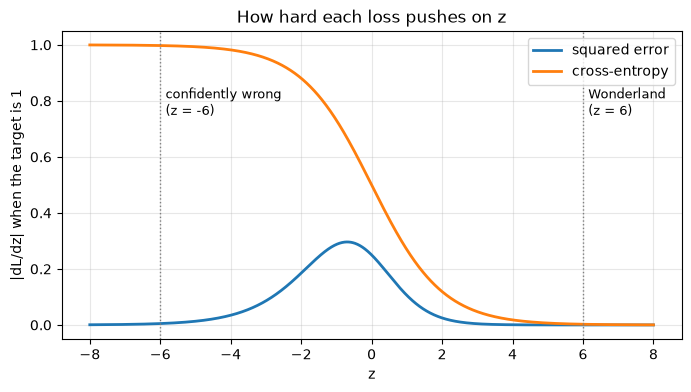

In [37]:
weights = w0.clone().requires_grad_(True)
y_hat = torch.sigmoid(torch.dot(weights, x) + b0)
F.binary_cross_entropy(y_hat, y).backward()

print("squared error gradient:", by_hand)
print("cross-entropy gradient:", weights.grad)
print(f"cross-entropy is {(weights.grad[0] / by_hand[0]).item():.0f} times larger here\n")

# dL/dz for a target of 1, over a range of z
z_vals = torch.linspace(-8, 8, 1601, requires_grad=True)
g_se = torch.autograd.grad(((torch.sigmoid(z_vals) - 1) ** 2).sum(), z_vals)[0]
g_ce = torch.autograd.grad(F.binary_cross_entropy(torch.sigmoid(z_vals), torch.ones(1601), reduction="sum"), z_vals)[0]

for zz in (-6.0, 0.0, 6.0):
    i = torch.argmin((z_vals - zz).abs())
    print(f"z = {zz:+.0f}:  squared error dL/dz = {g_se[i].item():+.5f}   cross-entropy dL/dz = {g_ce[i].item():+.5f}")

plt.figure(figsize=(8, 4))
plt.plot(z_vals.detach(), g_se.abs(), lw=2, label="squared error")
plt.plot(z_vals.detach(), g_ce.abs(), lw=2, label="cross-entropy")
for zz, txt in [(-6, "confidently wrong\n(z = -6)"), (6, "Wonderland\n(z = 6)")]:
    plt.axvline(zz, color="grey", ls=":", lw=1)
    plt.text(zz + 0.15, 0.75, txt, fontsize=9)
plt.xlabel("z")
plt.ylabel("|dL/dz| when the target is 1")
plt.title("How hard each loss pushes on z")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

At $z = 6$, cross-entropy pushes about 200 times harder than squared error. Both numbers are still small, which is fine, because the neuron is right.

The left side of the plot matters more. At $z = -6$ the neuron is confidently **wrong**: it outputs 0.0025 when the answer is 1. Squared error barely reacts ($|dL/dz| \approx 0.005$), because the sigmoid is flat out there and the slope wipes out the gradient. Cross-entropy pushes almost as hard as it can ($\approx 1$). So with squared error, a neuron that starts out badly wrong can take a very long time to recover. That is the main reason classifiers are trained with cross-entropy. The workshop uses squared error because its maths is easier to follow, which is fine for learning the idea.

### 3. Comparing learning rates

The Wonderland example is a single data point that the neuron already gets right, so every learning rate looks the same on it. For this comparison we switch to the OR gate data from `scripts/train_or_perceptron.py`. The neuron, the squared error loss, the update rule and the starting weights (seed 0) are all the same in every run, for 100 epochs. Only the learning rate $\eta$ changes.

    lr | loss ep 1 | loss ep 100 |          weights |    bias | outputs for 00, 01, 10, 11 | correct


----------------------------------------------------------------------------------------------------
  0.01 |    1.8006 |      0.9311 |     [2.03, 0.15] |   -1.52 | [0.179, 0.202, 0.624, 0.659] | 3/4
   0.1 |    1.7757 |      0.1903 |      [2.6, 1.83] |   -0.68 | [0.337, 0.761, 0.872, 0.977] | 4/4
     1 |    1.5343 |      0.0289 |     [4.41, 4.41] |   -1.92 | [0.128, 0.923, 0.924, 0.999] | 4/4
    10 |    1.0605 |      0.0023 |      [7.08, 7.1] |   -3.29 | [0.036, 0.978, 0.978, 1.0] | 4/4
   100 |    1.2250 |      1.0000 |    [26.05, 2.24] |   23.01 | [1.0, 1.0, 1.0, 1.0]       | 3/4

epochs where the loss went UP with lr = 10: [2]


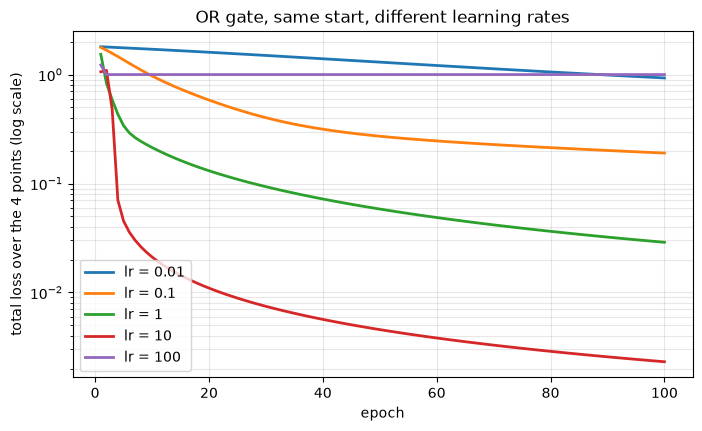

In [38]:
def train_or(lr, epochs=100, seed=0, reset_grads=True):
    torch.manual_seed(seed)
    w = torch.randn(2, requires_grad=True)
    b = torch.randn(1, requires_grad=True)
    history = []
    for epoch in range(epochs):
        total = 0.0
        for x_i, y_i in zip(X_or, y_or):
            loss = (torch.sigmoid(torch.dot(w, x_i) + b) - y_i) ** 2
            total += loss.item()
            loss.backward()
            with torch.no_grad():
                w -= lr * w.grad
                b -= lr * b.grad
            if reset_grads:
                w.grad.zero_()
                b.grad.zero_()
        history.append(total)
    return w.detach(), b.detach(), history

rates = [0.01, 0.1, 1, 10, 100]
runs = {lr: train_or(lr) for lr in rates}

print(f"{'lr':>6} | {'loss ep 1':>9} | {'loss ep 100':>11} | {'weights':>16} | {'bias':>7} | outputs for 00, 01, 10, 11 | correct")
print("-" * 100)
for lr, (w, b, hist) in runs.items():
    out = torch.sigmoid(X_or @ w + b)
    correct = int(((out >= 0.5).float() == y_or).sum())
    print(f"{lr:>6} | {hist[0]:>9.4f} | {hist[-1]:>11.4f} | {str([round(v, 2) for v in w.tolist()]):>16} | {b.item():>7.2f} | "
          f"{str([round(v, 3) for v in out.tolist()]):<26} | {correct}/4")

ups = [e + 2 for e in range(99) if runs[10][2][e + 1] > runs[10][2][e]]   # e + 2 = the later epoch, counting from 1
print("\nepochs where the loss went UP with lr = 10:", ups)

plt.figure(figsize=(8, 4.5))
for lr, (_, _, hist) in runs.items():
    plt.plot(range(1, 101), hist, lw=2, label=f"lr = {lr}")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("total loss over the 4 points (log scale)")
plt.title("OR gate, same start, different learning rates")
plt.grid(alpha=0.3, which="both")
plt.legend()
plt.show()

What we see, from smallest to largest:

- **0.01** is too slow. After 100 epochs the loss has only dropped from 1.80 to 0.93, and (0, 1) is still classified as 0 (output 0.20). It is heading the right way, just in very small steps.
- **0.1** (the workshop's value) gets all four right with a final loss of 0.19. The outputs are still soft, though: (0, 0) sits at 0.34.
- **1** converges much faster, to 0.029, with clear outputs.
- **10** reaches the lowest loss, 0.0023, but the curve isn't smooth. In epoch 2 the loss goes *up*, from 1.06 to 1.09, before falling. That is overshooting: the step is big enough to jump past the bottom of the valley.
- **100** breaks. The first few updates are so large that the bias jumps to about +23. That pushes $z$ deep into the flat top of the sigmoid for every input, so the neuron outputs 1 for everything, including (0, 0). The loss then sits at exactly 1.0 for the rest of training. It can't recover, because (as section 2 showed) the gradient on the flat part of the sigmoid is almost zero.

So a bigger learning rate isn't simply faster. It is faster up to a point. Beyond that, the weights get thrown into a region where learning stops. For this problem anything from 1 to 10 works well.

### 4. What `backward()`, `no_grad()` and `zero_()` actually do

Every training loop in the workshop has the same three lines around the update:

- `loss.backward()` works out the gradient for every tensor created with `requires_grad=True` and **adds** it to that tensor's `.grad`. It adds; it doesn't overwrite.
- `with torch.no_grad():` tells PyTorch that the update is not part of the model, so it shouldn't be recorded for the next backward pass.
- `.grad.zero_()` clears the stored gradient so that the next sample starts from zero.

The next three cells show what happens when each one is missing.

In [39]:
# backward() adds to .grad: same input and same weights, three calls in a row
weights = w0.clone().requires_grad_(True)
for k in range(1, 4):
    loss = (torch.sigmoid(torch.dot(weights, x) + b0) - y) ** 2
    loss.backward()
    print(f"after backward() call {k}: weights.grad = {[f'{v:.4e}' for v in weights.grad.tolist()]}")

after backward() call 1: weights.grad = ['-1.2197e-05', '-0.0000e+00', '-1.2197e-05']
after backward() call 2: weights.grad = ['-2.4394e-05', '-0.0000e+00', '-2.4394e-05']
after backward() call 3: weights.grad = ['-3.6591e-05', '-0.0000e+00', '-3.6591e-05']


Nothing changed between the calls, but the stored gradient goes 1×, 2×, 3×. In a training loop, that means each update would use the sum of every gradient so far instead of the current one. Here is the OR training from section 3 at $\eta = 1$, run with and without `zero_()`:

In [40]:
for reset in (True, False):
    w, b, hist = train_or(lr=1, epochs=30, reset_grads=reset)
    out = torch.sigmoid(X_or @ w + b)
    label = "with zero_()   " if reset else "without zero_()"
    print(f"{label}  loss at epochs 1, 6, 11, ..., 26: {[round(h, 4) for h in hist[::5]]}")
    print(f"{'':<17}weights = {[round(v, 2) for v in w.tolist()]}, bias = {b.item():.2f}, outputs = {[round(v, 3) for v in out.tolist()]}\n")

with zero_()     loss at epochs 1, 6, 11, ..., 26: [1.5343, 0.2923, 0.2016, 0.1554, 0.126, 0.1057]
                 weights = [3.2, 3.04], bias = -1.20, outputs = [0.232, 0.864, 0.881, 0.994]

without zero_()  loss at epochs 1, 6, 11, ..., 26: [1.4839, 0.9994, 1.0, 1.0, 1.0, 1.0]
                 weights = [63.72, 68.29], bias = 59.50, outputs = [1.0, 1.0, 1.0, 1.0]



Without `zero_()` the loss is already 0.9994 by epoch 6 and sits at 1.0 from then on. The weights grow to about 64 and 68 and the bias to about 59, so the neuron says 1 for every input. This is the same failure we got with $\eta = 100$, which makes sense: if gradients keep piling up, every step is bigger than the last. Forgetting `zero_()` behaves like a learning rate that grows on every step.

Finally, here is the update done *without* `torch.no_grad()`:

In [41]:
weights = w0.clone().requires_grad_(True)
loss = (torch.sigmoid(torch.dot(weights, x) + b0) - y) ** 2
loss.backward()
try:
    weights -= 0.1 * weights.grad      # no torch.no_grad() around this
except RuntimeError as err:
    print("RuntimeError:", err)

RuntimeError: a leaf Variable that requires grad is being used in an in-place operation.


PyTorch refuses. `weights` is a tensor that autograd is tracking, and changing it in place would corrupt the record autograd needs for the next backward pass. Inside `torch.no_grad()` the same line is allowed, because PyTorch then treats it as a parameter update rather than part of the forward pass.

### 5. Correcting the slide 5 weight update

The case study's breakdown of slide 5 skips the sigmoid. It treats the raw score $\hat y = 6$ as the output and uses $L = \frac12 (y - \hat y)^2$. That simplification is fine for teaching, but the gradient has the wrong sign. The slide uses $\frac{\partial L}{\partial w_j} = (y - \hat y)\,x_j$. Differentiating properly:

$$
\frac{\partial L}{\partial w_j} = \tfrac12 \cdot 2(y - \hat y)\cdot \frac{\partial (y - \hat y)}{\partial w_j} = (y - \hat y)(-x_j) = (\hat y - y)\,x_j
$$

The minus sign comes from $\hat y$ having a minus in front of it inside the bracket. With $\hat y - y = 5$, the gradients are $[5, 0, 5]$, not $[-5, 0, -5]$. Autograd agrees:

In [42]:
weights = w0.clone().requires_grad_(True)
y_hat_raw = torch.dot(weights, x) + b0          # no sigmoid, as on the slide
loss = 0.5 * (y - y_hat_raw) ** 2
loss.backward()
print("gradient from autograd:", weights.grad.tolist(), "\n")

with torch.no_grad():
    corrected = weights - 0.1 * weights.grad
slide = torch.tensor([5.5, 2.0, 4.5])

for name, w in [("before the update", w0), ("corrected update", corrected), ("slide 5 update", slide)]:
    out = (torch.dot(w, x) + b0).item()
    print(f"{name:<18} w = {[round(v, 2) for v in w.tolist()]}   y_hat = {out:.1f}   error y - y_hat = {1 - out:+.1f}")

gradient from autograd: [5.0, 0.0, 5.0] 

before the update  w = [5.0, 2.0, 4.0]   y_hat = 6.0   error y - y_hat = -5.0
corrected update   w = [4.5, 2.0, 3.5]   y_hat = 5.0   error y - y_hat = -4.0
slide 5 update     w = [5.5, 2.0, 4.5]   y_hat = 7.0   error y - y_hat = -6.0


The corrected weights $[4.5, 2, 3.5]$ bring the output down from 6 to 5, closer to the target of 1. The slide's weights $[5.5, 2, 4.5]$ push it up to 7, further away. That contradicts the slide's own sentence that the new weights "will produce a smaller output". A quick sanity check for any gradient step is that after the update the error should shrink, not grow.

### 6. From gradient descent to backpropagation

**Homework question:** how is this update rule related to backpropagation in multi-layer networks?

Gradient descent is the update itself, $w \leftarrow w - \eta\,\partial L / \partial w$. It doesn't say how to get $\partial L / \partial w$. For a single neuron that was easy, because every weight is one chain-rule step away from the output.

In a network with a hidden layer, a first-layer weight only reaches the loss indirectly: it feeds a hidden neuron, which feeds the output neuron, which feeds the loss. Backpropagation is how those gradients are worked out efficiently: it applies the chain rule one layer at a time, starting at the output and moving backwards. For one hidden layer, with sigmoid everywhere and cross-entropy loss:

$$
\delta^{(2)} = \hat y - y \qquad \text{(error at the output neuron's } z \text{)}
$$
$$
\delta^{(1)} = \big(\delta^{(2)}\, W^{(2)}\big) \odot h\,(1-h) \qquad \text{(error sent back to the hidden layer)}
$$
$$
\frac{\partial L}{\partial W^{(2)}} = \delta^{(2)\top} h, \qquad
\frac{\partial L}{\partial W^{(1)}} = \delta^{(1)\top} x
$$

The hidden layer's error is the output error sent back through the same weights $W^{(2)}$, then scaled by the hidden neurons' own sigmoid slope. Each layer reuses the $\delta$ already computed for the layer after it, so nothing is calculated twice. Once all the gradients are known, every weight is updated with the same gradient descent rule as before. In short, backprop finds the gradients and gradient descent uses them.

To try this on a problem one neuron can't solve, we train a 2-2-1 network on XOR, which Davisen's section proved is impossible for a single perceptron. First we check one backward pass by hand against autograd.

In [43]:
X_xor = X_or.clone()
y_xor = torch.tensor([[0.], [1.], [1.], [0.]])

def init_net(seed):
    torch.manual_seed(seed)
    W1 = torch.randn(2, 2, requires_grad=True)    # hidden layer: 2 neurons, 2 inputs each
    b1 = torch.zeros(2, requires_grad=True)
    W2 = torch.randn(1, 2, requires_grad=True)    # output neuron: 2 inputs (the hidden neurons)
    b2 = torch.zeros(1, requires_grad=True)
    return [W1, b1, W2, b2]

def forward(params, X):
    W1, b1, W2, b2 = params
    h = torch.sigmoid(X @ W1.T + b1)
    out = torch.sigmoid(h @ W2.T + b2)
    return h, out

params = init_net(seed=2)
h, out = forward(params, X_xor)
F.binary_cross_entropy(out, y_xor).backward()

with torch.no_grad():
    W1, b1, W2, b2 = params
    n = len(X_xor)
    d2 = (out - y_xor) / n             # output error (divided by n because the loss is averaged over the 4 rows)
    d1 = (d2 @ W2) * h * (1 - h)       # error sent back to the hidden layer
    by_hand = [d1.T @ X_xor, d1.sum(0), d2.T @ h, d2.sum(0)]

for name, g, p in zip(["W1", "b1", "W2", "b2"], by_hand, params):
    print(f"{name}: by hand = {[round(v, 5) for v in g.flatten().tolist()]}   matches autograd: {torch.allclose(g, p.grad, atol=1e-7)}")

W1: by hand = [0.01376, 0.01247, 0.00168, -0.00238]   matches autograd: True
b1: by hand = [0.02259, -0.00831]   matches autograd: True
W2: by hand = [0.04354, 0.02864]   matches autograd: True
b2: by hand = [0.08243]   matches autograd: True


The hand-written backward pass matches autograd for all four parameter tensors. Now we train with autograd, using the same loop as before, and try six different random starting points.

In [44]:
def train_xor(seed, lr=1.0, epochs=5000):
    params = init_net(seed)
    for epoch in range(epochs):
        _, out = forward(params, X_xor)
        loss = F.binary_cross_entropy(out, y_xor)
        loss.backward()
        with torch.no_grad():
            for p in params:
                p -= lr * p.grad
                p.grad.zero_()
    return params, loss.item()

params, final_loss = train_xor(seed=2)
h, out = forward(params, X_xor)
print(f"seed 2, final loss = {final_loss:.4f}")
for x_i, h_i, o_i in zip(X_xor.int().tolist(), h.detach(), out.detach()):
    print(f"  x = {x_i}   hidden = ({h_i[0]:.2f}, {h_i[1]:.2f})   output = {o_i.item():.3f}   predicted = {int(o_i.item() >= 0.5)}")

print("\nsix random starts:")
for seed in range(6):
    p, l = train_xor(seed)
    _, o = forward(p, X_xor)
    solved = bool(((o >= 0.5).float() == y_xor).all())
    print(f"  seed {seed}: loss = {l:.4f}   outputs = {[round(v, 3) for v in o.detach().flatten().tolist()]}   solved XOR: {solved}")

seed 2, final loss = 0.0021
  x = [0, 0]   hidden = (1.00, 0.96)   output = 0.002   predicted = 0
  x = [0, 1]   hidden = (0.95, 0.01)   output = 0.998   predicted = 1
  x = [1, 0]   hidden = (0.95, 0.01)   output = 0.998   predicted = 1
  x = [1, 1]   hidden = (0.04, 0.00)   output = 0.003   predicted = 0

six random starts:


  seed 0: loss = 0.3480   outputs = [0.001, 0.998, 0.5, 0.501]   solved XOR: False


  seed 1: loss = 0.0070   outputs = [0.006, 0.992, 0.992, 0.005]   solved XOR: True


  seed 2: loss = 0.0021   outputs = [0.002, 0.998, 0.998, 0.003]   solved XOR: True


  seed 3: loss = 0.0021   outputs = [0.002, 0.998, 0.998, 0.002]   solved XOR: True


  seed 4: loss = 0.3480   outputs = [0.002, 0.999, 0.499, 0.501]   solved XOR: False


  seed 5: loss = 0.3478   outputs = [0.001, 0.999, 0.499, 0.501]   solved XOR: False


With seed 2 the network learns XOR, and every output is within 0.003 of its target. The hidden columns show how it did it. Hidden neuron 1 is off only for $[1, 1]$, so it behaves like **NAND**. Hidden neuron 2 is on only for $[0, 0]$, so it behaves like **NOR**. The output fires when the first is on and the second is off, which is NAND AND (NOT NOR) = NAND AND OR. That is the same decomposition Davisen built by hand, except here the network found it on its own from random weights.

The six random starts show the catch. Three of them (seeds 0, 4 and 5) stop at a loss of about 0.348 and leave two of the inputs sitting on the fence at 0.5. The gradient there is close to zero, but the answer is still wrong. This is a **local minimum**. Gradient descent only ever walks downhill from wherever it starts, so the starting weights matter. This never happened with the single neuron, whose loss surface has only one valley. With a hidden layer there can be several. In practice it is handled with more hidden neurons than the bare minimum, or by simply restarting from different random weights.

### 7. The training script and what the debugger shows

We added `--lr` and `--epochs` options to `scripts/train_or_perceptron.py`, plus a printout of what the trained neuron predicts. That printout exposed something the original output hides. With the default settings ($\eta = 0.1$, 20 epochs) the loss falls to 0.58, but the "trained" neuron still gets (0, 1) wrong:

| command | (0, 0) | (0, 1) | (1, 0) | (1, 1) |
|---|---|---|---|---|
| `python scripts/train_or_perceptron.py` | 0.249 | **0.356 (wrong)** | 0.759 | 0.839 |
| `python scripts/train_or_perceptron.py --epochs 200` | 0.272 | 0.822 | 0.871 | 0.988 |
| `python scripts/train_or_perceptron.py --lr 1` | 0.277 | 0.837 | 0.875 | 0.989 |

Ten times the epochs and ten times the learning rate end up in almost the same place. While the gradients are small and fairly steady, ten small steps cover about the same ground as one step ten times bigger. (Section 3 showed where that stops being true.)

We ran the script in the VS Code debugger with a breakpoint on `loss.backward()` and stepped through the first two samples:

- Before the first call, `weights.grad` is `None`. PyTorch only creates the `.grad` tensor the first time `backward()` runs.
- The first sample is $x = [0, 0]$ with target 0. So $z$ is just the bias, $-2.179$, giving $\hat y = 0.102$ and a loss of 0.0103.
- After `backward()`, `weights.grad` is `[0, 0]` and `bias.grad` is 0.0186. With both inputs at 0, only the bias gets any blame, the same thing we saw with $w_2$ in section 1.
- After the update the bias moves from $-2.1788$ to $-2.1806$, and the weights don't move at all.
- On the second sample, $x = [0, 1]$, only the second weight and the bias get gradients (both $-0.132$), because $x_1 = 0$.

### Talking points

1. **A gradient is a product of local slopes, and the sigmoid's slope is usually the bottleneck.** At the Wonderland point $\sigma'(6) \approx 0.0025$, so one update moves $w_1$ by about one millionth. With squared error, a neuron that is confidently *wrong* barely learns either. Cross-entropy cancels the sigmoid slope, so it learns hardest exactly when it is most wrong.
2. **The learning rate isn't a speed dial.** On the OR gate, 0.01 was too slow, 1 to 10 worked well, and 100 threw the weights into the flat part of the sigmoid, where learning stopped for good. Forgetting `grad.zero_()` caused exactly the same failure, because gradients that pile up act like an ever-growing learning rate.
3. **Backpropagation finds the gradients and gradient descent uses them.** Backprop is the chain rule applied one layer at a time, reusing each layer's error. Together they learned XOR, which no single perceptron can. But they only walk downhill from where they start, and three of our six random starts got stuck in a local minimum.